# NLP Assignment 2: Embeddings and Hidden Markov Models

**Alexandria University — Computer and Systems Department — Natural Language Processing**

This notebook is the complete, self-contained submission. Every algorithm is implemented from scratch in the cells
below using only Python and NumPy. The Hugging Face `datasets` library is used only to download CoNLL-2000, and
`matplotlib` only for plots.

| Part | Content |
|---|---|
| **0** | Setup, data loading, reproducible train/validation split |
| **1** | Preprocessing & vocabulary, PMI, TF-IDF, Word2Vec (SGNS, with manually derived gradients), comparison |
| **2** | HMM estimation with smoothing and unknown-word handling, log-space Viterbi, evaluation |
| **3** | Embedding-assisted HMMs (PMI / TF-IDF / Word2Vec), four-way comparison, error analysis |

All hyperparameters are tuned on the validation split. The test partition is used only for the final evaluations
(Sections 2.4 and 3.2).

# Part 0: Setup and Data

In [1]:
import sys, time, math, re, random, itertools
from collections import Counter, defaultdict
from collections.abc import Callable
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Locate the project root (has a data/ folder) so the HF cache is reused; works in Colab too.
ROOT = Path.cwd()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    ROOT = Path.cwd()
DATA_CACHE = ROOT / "data" / "hf_cache"
OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [2]:
DATASET_NAME = "eriktks/conll2000"
# The original repo ships a loading script, which recent `datasets` versions refuse to run.
# The Hub's auto-converted parquet branch contains exactly the same data.
DATASET_REVISION = "refs/convert/parquet"

Sentence = list[tuple[str, str]]  # [(token, pos_tag), ...]


def load_conll2000(cache_dir=DATA_CACHE) -> dict[str, list[Sentence]]:
    """Return {'train': [...], 'test': [...]} with each sentence as [(token, tag), ...].

    Only `tokens` and `pos_tags` are used; chunk labels are discarded.
    """
    from datasets import load_dataset  # used ONLY to fetch the raw data

    ds = load_dataset(DATASET_NAME, revision=DATASET_REVISION, cache_dir=str(cache_dir))
    tag_names = ds["train"].features["pos_tags"].feature.names
    return {
        split: [[(tok, tag_names[t]) for tok, t in zip(ex["tokens"], ex["pos_tags"])] for ex in ds[split]]
        for split in ("train", "test")
    }


def train_val_split(sentences, val_fraction=0.1, seed=42):
    """Reproducible random sentence-level split of the training partition."""
    idx = list(range(len(sentences)))
    random.Random(seed).shuffle(idx)
    val_idx = set(idx[: int(round(len(sentences) * val_fraction))])
    train = [s for i, s in enumerate(sentences) if i not in val_idx]
    val = [s for i, s in enumerate(sentences) if i in val_idx]
    return train, val


def words_of(sentence): return [w for w, _ in sentence]
def tags_of(sentence):  return [t for _, t in sentence]


data = load_conll2000()
train_sents, val_sents = train_val_split(data["train"], val_fraction=0.1, seed=SEED)
test_sents = data["test"]
print(f"train: {len(train_sents)} sentences / {sum(map(len, train_sents))} tokens")
print(f"val:   {len(val_sents)} sentences / {sum(map(len, val_sents))} tokens")
print(f"test:  {len(test_sents)} sentences / {sum(map(len, test_sents))} tokens")
print("example:", train_sents[0][:8])

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

train: 8043 sentences / 190943 tokens
val:   894 sentences / 20784 tokens
test:  2013 sentences / 47377 tokens
example: [('Confidence', 'NN'), ('in', 'IN'), ('the', 'DT'), ('pound', 'NN'), ('is', 'VBZ'), ('widely', 'RB'), ('expected', 'VBN'), ('to', 'TO')]


The original training partition is split 90/10 into train/validation with a fixed seed (42), so the split is
reproducible. All tuning uses the validation set; the test partition is touched only once, for the final evaluation.
Chunk labels are dropped at load time.

# Part 1: Sparse and Dense Word Representations

## 1.1 Preprocessing and Vocabulary

The representations in Part 1 model *distributional* similarity, so the preprocessing tries to concentrate
co-occurrence counts on meaningful word types:

* **Lowercasing**: *The* / *the* and *Market* / *market* are the same lexical item for distributional purposes. Without
  lowercasing, sentence-initial forms would get their own, much sparser vectors. (Case still matters for POS tagging, so
  Part 2 keeps the raw tokens.)
* **Number normalisation → `<NUM>`**: CoNLL-2000 is Wall Street Journal text full of prices, percentages and dates
  (`1\/4`, `3.5`, `1989`). Each individual number is rare, but all of them behave alike. Collapsing them into one token
  gives one well-estimated vector instead of thousands of noisy ones.
* **Dropping pure-punctuation tokens**: commas, periods and quotes appear in almost every window. They add a lot of
  co-occurrence counts but little semantic signal, and they would dominate raw counts. Tokens that only contain
  punctuation (e.g. `'s`, `n't`, `mr.`) are kept.
* **Minimum count**: words below `min_count` in the training split are removed. Their vectors would come from one or two
  contexts, which is pure noise, and they inflate the vocabulary (and with it the matrix size). The table below shows the
  trade-off. `min_count = 2` halves the vocabulary (14.8k → 7.9k) while keeping 96% of the normalised tokens.
  `min_count` is tuned separately for each representation on validation data (see 1.2–1.4).
* The vocabulary is built **only from the training split**. Validation and test words not in it are OOV.

No stemming or stop-word removal is applied. Inflection (*rose* vs *rises*) and function words are exactly the
signals that make neighbours syntactically similar, which Part 3 relies on.

In [3]:
"""Text normalization and vocabulary construction from training sentences."""


import re
from collections import Counter

UNK_TOKEN = "<UNK>"
NUM_TOKEN = "<NUM>"

_NUMBER_RE = re.compile(r"^[+-]?[\d.,:/\-]*\d[\d.,:/\-]*%?$")
_PUNCT_RE = re.compile(r"^[^\w\s]+$")


def normalize_token(
    token: str,
    lowercase: bool = True,
    normalize_numbers: bool = True,
    drop_punctuation: bool = True,
) -> str | None:
    """Return normalized token or None if it should be dropped."""
    t = token.strip()
    if not t:
        return None
    if drop_punctuation and _PUNCT_RE.match(t):
        return None
    if normalize_numbers and _NUMBER_RE.match(t):
        return NUM_TOKEN
    if lowercase:
        t = t.lower()
    return t


class Vocabulary:
    """Training-set vocabulary mapping normalized tokens <-> integer IDs."""

    def __init__(
        self,
        min_count: int = 2,
        lowercase: bool = True,
        normalize_numbers: bool = True,
        drop_punctuation: bool = True,
    ):
        self.min_count = min_count
        self.lowercase = lowercase
        self.normalize_numbers = normalize_numbers
        self.drop_punctuation = drop_punctuation

        self.word2idx: dict[str, int] = {}
        self.idx2word: list[str] = []
        self.counts: list[int] = []
        self.raw_token_count: int = 0
        self.kept_token_count: int = 0

    def normalize(self, token: str) -> str | None:
        return normalize_token(
            token,
            lowercase=self.lowercase,
            normalize_numbers=self.normalize_numbers,
            drop_punctuation=self.drop_punctuation,
        )

    def normalize_sentence(self, tokens: list[str]) -> list[str]:
        out: list[str] = []
        for tok in tokens:
            norm = self.normalize(tok)
            if norm is not None:
                out.append(norm)
        return out

    def fit(self, sentences: list[list[str]]) -> "Vocabulary":
        """Build vocabulary strictly from training sentences."""
        counter: Counter[str] = Counter()
        raw_total = 0
        for sent in sentences:
            raw_total += len(sent)
            for tok in sent:
                norm = self.normalize(tok)
                if norm is not None:
                    counter[norm] += 1

        # Sort by descending frequency, then alphabetically for determinism
        kept = sorted(
            [(w, c) for w, c in counter.items() if c >= self.min_count],
            key=lambda x: (-x[1], x[0]),
        )

        self.idx2word = [w for w, _ in kept]
        self.counts = [c for _, c in kept]
        self.word2idx = {w: i for i, w in enumerate(self.idx2word)}
        self.raw_token_count = raw_total
        self.kept_token_count = sum(self.counts)
        return self

    def encode_sentence(self, tokens: list[str], drop_oov: bool = True) -> list[int]:
        """Convert raw sentence tokens into vocabulary indices."""
        ids: list[int] = []
        for tok in tokens:
            norm = self.normalize(tok)
            if norm is None:
                continue
            idx = self.word2idx.get(norm)
            if idx is not None:
                ids.append(idx)
            elif not drop_oov:
                ids.append(-1)
        return ids

    def __len__(self) -> int:
        return len(self.idx2word)

    def __contains__(self, word: str) -> bool:
        norm = self.normalize(word)
        return norm is not None and norm in self.word2idx

In [4]:
train_word_sents = [words_of(s) for s in train_sents]
val_word_sents = [words_of(s) for s in val_sents]

for mc in [1, 2, 3, 5]:
    v = Vocabulary(min_count=mc).fit(train_word_sents)
    print(
        f"min_count={mc}: vocab_size={len(v):>5} | "
        f"kept_tokens={v.kept_token_count:>6}/{v.raw_token_count} "
        f"({v.kept_token_count / v.raw_token_count:.1%})"
    )

vocab = Vocabulary(min_count=2).fit(train_word_sents)
print("\nTop 15 normalized tokens:", list(zip(vocab.idx2word[:15], vocab.counts[:15])))
print("\nExample:", train_word_sents[3][:14], "\n   ->  ", vocab.normalize_sentence(train_word_sents[3][:14]))

min_count=1: vocab_size=14779 | kept_tokens=166606/190943 (87.3%)
min_count=2: vocab_size= 7871 | kept_tokens=159698/190943 (83.6%)


min_count=3: vocab_size= 5630 | kept_tokens=155216/190943 (81.3%)


min_count=5: vocab_size= 3683 | kept_tokens=148634/190943 (77.8%)

Top 15 normalized tokens: [('the', 9724), ('<NUM>', 5073), ('of', 4714), ('to', 4564), ('a', 4011), ('in', 3425), ('and', 3327), ('for', 1785), ("'s", 1726), ('that', 1720), ('is', 1264), ('it', 1084), ('said', 1076), ('on', 1047), ('at', 966)]

Example: ['This', 'has', 'increased', 'the', 'risk', 'of', 'the', 'government', 'being', 'forced', 'to', 'increase', 'base', 'rates'] 
   ->   ['this', 'has', 'increased', 'the', 'risk', 'of', 'the', 'government', 'being', 'forced', 'to', 'increase', 'base', 'rates']


### Intrinsic validation metric

The assignment uses the representations to help a POS tagger, so representations are tuned with a metric that
measures exactly that. For 400 validation words that are in the training vocabulary, we retrieve the top-5 neighbours and
measure the fraction whose **majority training POS tag** matches the query's ("POS-agreement@5"). The validation split
only decides *which* words are queried. No test data is used.

In [5]:
tag_by_norm = {}
for s in train_sents:
    for w, t in s:
        nw = vocab.normalize(w)
        if nw is not None:
            tag_by_norm.setdefault(nw, Counter())[t] += 1
word_majority_tag = {w: cnt.most_common(1)[0][0] for w, cnt in tag_by_norm.items()}

val_eval_words = sorted({
    nw for s in val_word_sents for w in s
    if (nw := vocab.normalize(w)) is not None and nw in vocab.word2idx
})[:400]


def neighbor_pos_agreement(model, query_words, k=5):
    matches, total = 0, 0
    for w in query_words:
        g_tag = word_majority_tag.get(w)
        if not g_tag:
            continue
        for nw, _ in model.most_similar(w, top_k=k):
            matches += word_majority_tag.get(nw) == g_tag
            total += 1
    return matches / max(1, total)

## 1.2 PMI

We build a symmetric **word–context co-occurrence matrix** $C$ using a ±$W$-token window inside each sentence. Each
(word, context) count is then reweighted with pointwise mutual information:

$$\mathrm{PMI}(w,c) = \log_2 \frac{P(w,c)}{P(w)\,P(c)} = \log_2\frac{C(w,c)\cdot |D|}{C(w,\cdot)\,C(\cdot,c)}$$

where $|D|$ is the total number of co-occurrence pairs. With `positive=True` we use **PPMI**,
$\max(0,\mathrm{PMI})$. With `positive=False`, all *observed* (word, context) pairs keep their PMI value, including
negative ones. Unobserved pairs would have PMI $=-\infty$ and are left as implicit zeros either way.

**Sparse storage.** The $|V|\times|V|$ matrix is more than 99% zeros, so each row is a `dict{context_id: weight}`, and
an **inverted index** `context_id → [(word_id, weight)]` is built as well. A cosine nearest-neighbour query then
only touches words that share at least one context with the query. This is far cheaper than a dense
$|V|\times|V|$ product.

In [6]:
"""Sparse Pointwise Mutual Information (PMI / PPMI) word representations."""


import math
import sys
from collections import defaultdict

import numpy as np


class PMIRepresentation:
    """Word-context co-occurrence matrix weighted by PMI or Positive PMI (PPMI)."""

    def __init__(
        self,
        window_size: int = 4,
        positive: bool = True,
        min_count: int = 2,
        lowercase: bool = True,
        normalize_numbers: bool = True,
        drop_punctuation: bool = True,
    ):
        self.window_size = window_size
        self.positive = positive
        self.vocab = Vocabulary(
            min_count=min_count,
            lowercase=lowercase,
            normalize_numbers=normalize_numbers,
            drop_punctuation=drop_punctuation,
        )

        # Sparse row storage: word_id -> {context_id: pmi_weight}
        self.vectors: list[dict[int, float]] = []
        # Inverted index: context_id -> [(word_id, pmi_weight), ...]
        self._inverted: dict[int, list[tuple[int, float]]] = {}
        self.norms: np.ndarray = np.empty(0, dtype=np.float64)
        self.nnz: int = 0
        self.total_pairs: float = 0.0

    def fit(self, sentences: list[list[str]]) -> "PMIRepresentation":
        self.vocab.fit(sentences)
        V = len(self.vocab)

        cooc: dict[int, dict[int, float]] = defaultdict(lambda: defaultdict(float))
        row_sums = np.zeros(V, dtype=np.float64)
        col_sums = np.zeros(V, dtype=np.float64)
        total = 0.0

        W = self.window_size
        for sent in sentences:
            ids = self.vocab.encode_sentence(sent, drop_oov=True)
            L = len(ids)
            for i, w in enumerate(ids):
                left = max(0, i - W)
                right = min(L, i + W + 1)
                for j in range(left, right):
                    if i == j:
                        continue
                    c = ids[j]
                    cooc[w][c] += 1.0
                    row_sums[w] += 1.0
                    col_sums[c] += 1.0
                    total += 1.0

        self.total_pairs = total
        self.vectors = [{} for _ in range(V)]
        inverted: dict[int, list[tuple[int, float]]] = defaultdict(list)
        self.norms = np.zeros(V, dtype=np.float64)
        nnz = 0

        if total > 0:
            for w, ctx_dict in cooc.items():
                rw = row_sums[w]
                if rw <= 0:
                    continue
                row_vec: dict[int, float] = {}
                sq_sum = 0.0
                for c, count in ctx_dict.items():
                    cc = col_sums[c]
                    if cc <= 0:
                        continue
                    pmi = math.log2((count * total) / (rw * cc))
                    if self.positive and pmi <= 0.0:
                        continue
                    row_vec[c] = pmi
                    sq_sum += pmi * pmi
                    inverted[c].append((w, pmi))
                    nnz += 1
                self.vectors[w] = row_vec
                self.norms[w] = math.sqrt(sq_sum)

        self._inverted = dict(inverted)
        self.nnz = nnz
        return self

    def _resolve_id(self, word: str) -> int | None:
        norm = self.vocab.normalize(word)
        if norm is None:
            return None
        return self.vocab.word2idx.get(norm)

    def get_vector(self, word: str) -> dict[int, float] | None:
        idx = self._resolve_id(word)
        return self.vectors[idx] if idx is not None else None

    def similarity(self, w1: str, w2: str) -> float:
        i1 = self._resolve_id(w1)
        i2 = self._resolve_id(w2)
        if i1 is None or i2 is None:
            return 0.0
        n1, n2 = self.norms[i1], self.norms[i2]
        if n1 == 0.0 or n2 == 0.0:
            return 0.0

        v1, v2 = self.vectors[i1], self.vectors[i2]
        if len(v1) > len(v2):
            v1, v2 = v2, v1
        dot = sum(val * v2.get(k, 0.0) for k, val in v1.items())
        return float(dot / (n1 * n2))

    def _query_sparse_vector(
        self,
        q_vec: dict[int, float],
        top_k: int = 10,
        exclude_id: int | None = None,
    ) -> list[tuple[str, float]]:
        q_norm = math.sqrt(sum(v * v for v in q_vec.values()))
        if q_norm == 0.0:
            return []

        dots: dict[int, float] = defaultdict(float)
        for ctx_id, q_val in q_vec.items():
            for cand_id, cand_val in self._inverted.get(ctx_id, ()):
                if cand_id != exclude_id:
                    dots[cand_id] += q_val * cand_val

        scored: list[tuple[str, float]] = []
        for cand_id, dot in dots.items():
            c_norm = self.norms[cand_id]
            if c_norm > 0.0:
                scored.append((self.vocab.idx2word[cand_id], dot / (q_norm * c_norm)))

        scored.sort(key=lambda x: x[1], reverse=True)
        return scored[:top_k]

    def most_similar(self, word: str, top_k: int = 10) -> list[tuple[str, float]]:
        idx = self._resolve_id(word)
        if idx is None or self.norms[idx] == 0.0:
            return []
        return self._query_sparse_vector(self.vectors[idx], top_k=top_k, exclude_id=idx)

    def most_similar_from_context(
        self, context_words: list[str], top_k: int = 10
    ) -> list[tuple[str, float]]:
        """Find words that occur in the same local contexts (useful for OOV words in Part 3)."""
        q_vec: dict[int, float] = defaultdict(float)
        for cw in context_words:
            cid = self._resolve_id(cw)
            if cid is not None:
                q_vec[cid] += 1.0
        return self._query_sparse_vector(q_vec, top_k=top_k)

    @property
    def shape(self) -> tuple[int, int]:
        V = len(self.vocab)
        return (V, V)

    @property
    def sparsity(self) -> float:
        V = len(self.vocab)
        total_cells = V * V
        return 1.0 - (self.nnz / total_cells) if total_cells > 0 else 1.0

    def storage_bytes(self) -> int:
        """Approximate memory footprint in bytes of the sparse representation."""
        total = sys.getsizeof(self.vectors) + self.norms.nbytes
        for row in self.vectors:
            total += sys.getsizeof(row)
            # int key + float value overhead in Python dict
            total += len(row) * (sys.getsizeof(0) + sys.getsizeof(0.0))
        return total

In [7]:
print("Tuning PMI on validation words (top-5 neighbor POS agreement):")
best_pmi_cfg, best_pmi_score = None, -1.0
for mc in [2, 3]:
    for win in [2, 4, 6]:
        for pos in [True, False]:
            m = PMIRepresentation(window_size=win, positive=pos, min_count=mc).fit(train_word_sents)
            score = neighbor_pos_agreement(m, val_eval_words, k=5)
            print(f"  min_count={mc}, window={win}, positive={str(pos):<5} -> POS-agree={score:.4f}, nnz={m.nnz}")
            if score > best_pmi_score:
                best_pmi_score = score
                best_pmi_cfg = dict(window_size=win, positive=pos, min_count=mc)

pmi_model = PMIRepresentation(**best_pmi_cfg).fit(train_word_sents)
print("\nSelected PMI config:", best_pmi_cfg)
print(f"PMI matrix: {pmi_model.shape[0]} x {pmi_model.shape[1]}, nnz={pmi_model.nnz}, sparsity={pmi_model.sparsity:.2%}")

# How PMI differs from raw co-occurrence counts, shown on "market"
q = "market"
qid = pmi_model._resolve_id(q)
raw_cooc = Counter()
W = best_pmi_cfg["window_size"]
for sent in train_word_sents:
    ids = pmi_model.vocab.encode_sentence(sent)
    for i, w in enumerate(ids):
        if w == qid:
            for j in range(max(0, i - W), min(len(ids), i + W + 1)):
                if i != j:
                    raw_cooc[pmi_model.vocab.idx2word[ids[j]]] += 1

top_pmi_ctx = sorted(pmi_model.vectors[qid].items(), key=lambda x: x[1], reverse=True)[:8]
print(f"\nTop contexts for '{q}' by RAW count:", raw_cooc.most_common(8))
print(f"Top contexts for '{q}' by PMI:      ", [(pmi_model.vocab.idx2word[i], round(v, 2)) for i, v in top_pmi_ctx])

Tuning PMI on validation words (top-5 neighbor POS agreement):


  min_count=2, window=2, positive=True  -> POS-agree=0.2491, nnz=256445


  min_count=2, window=2, positive=False -> POS-agree=0.2496, nnz=278056


  min_count=2, window=4, positive=True  -> POS-agree=0.2025, nnz=448389


  min_count=2, window=4, positive=False -> POS-agree=0.2025, nnz=493771


  min_count=2, window=6, positive=True  -> POS-agree=0.1925, nnz=594690


... (4 outputs left out)

  min_count=3, window=4, positive=False -> POS-agree=0.2049, nnz=447583


  min_count=3, window=6, positive=True  -> POS-agree=0.1967, nnz=528674


  min_count=3, window=6, positive=False -> POS-agree=0.1907, nnz=594873



Selected PMI config: {'window_size': 2, 'positive': False, 'min_count': 3}
PMI matrix: 5630 x 5630, nnz=254330, sparsity=99.20%

Top contexts for 'market' by RAW count: [('the', 211), ('stock', 48), ('a', 38), ("'s", 31), ('in', 27), ('and', 26), ('to', 25), ('of', 21)]
Top contexts for 'market' by PMI:       [('bull', 6.49), ('new-issue', 6.49), ('strategist', 6.33), ('gyrations', 6.23), ('commentary', 6.07), ('participants', 6.06), ('secondary', 6.05), ('anymore', 5.81)]


**PMI vs raw counts.** By raw count the strongest contexts of *market* are *the, a, 's, in, and, to, of*. These are
frequent function words that co-occur with *every* noun, so raw-count vectors of almost all nouns point the same way,
and cosine similarity mostly measures word frequency. PMI divides by the expected count $P(w)P(c)$. This pushes those
function words down to ~0 and promotes contexts that are *specific* to the word (*bull, new-issue, strategist,
gyrations, participants*). These are the contexts that separate *market* from other nouns.

PMI's weakness is the opposite one: it is unreliable for **rare** pairs. A context seen once with a rare word can get a
huge PMI, which is why the top PMI contexts are dominated by low-frequency words. Raising `min_count` (2 → 3) helped on
validation for this reason.

**Selected hyperparameters.** A **narrow window (±2)** was clearly best (0.265 vs ~0.20 for ±4/±6). Close neighbours
carry *syntactic* information (determiner → noun, auxiliary → participle), while wide windows drift toward topical
association. Topical similarity is less useful for our POS-oriented goal and also makes the matrix 2–3× denser.
`positive=False` and PPMI were essentially tied (0.2650 vs 0.2639). The negative-PMI entries are a small fraction of the
non-zeros and change the neighbours very little.

## 1.3 TF-IDF

Each **sentence is a document**. A word's vector lives in $\mathbb{R}^{|D|}$ ($|D|$ = number of training sentences):

$$\text{tfidf}(w,d) = \text{tf}(w,d)\cdot \log\frac{|D|}{\text{df}(w)}, \qquad \text{tf} = \text{raw count} \;\;\text{or}\;\; 1+\log(\text{count})\;\text{(sublinear)}$$

Two words are similar when they occur in the **same sentences**. The IDF factor down-weights words that occur in many
sentences (here mainly function words that survived preprocessing). The same row-dict + inverted-index sparse storage
as PMI is used, with sentences as the columns.

In [8]:
"""Sparse sentence-level TF-IDF word representations."""


import math
import sys
from collections import Counter, defaultdict

import numpy as np


class TFIDFRepresentation:
    """Word-document TF-IDF representation treating each sentence as a document."""

    def __init__(
        self,
        sublinear_tf: bool = False,
        min_count: int = 2,
        lowercase: bool = True,
        normalize_numbers: bool = True,
        drop_punctuation: bool = True,
    ):
        self.sublinear_tf = sublinear_tf
        self.vocab = Vocabulary(
            min_count=min_count,
            lowercase=lowercase,
            normalize_numbers=normalize_numbers,
            drop_punctuation=drop_punctuation,
        )

        # Sparse row storage: word_id -> {sent_id: tfidf_weight}
        self.vectors: list[dict[int, float]] = []
        # Inverted index: sent_id -> [(word_id, tfidf_weight), ...]
        self._inverted: dict[int, list[tuple[int, float]]] = {}
        self.idf: np.ndarray = np.empty(0, dtype=np.float64)
        self.norms: np.ndarray = np.empty(0, dtype=np.float64)
        self.num_docs: int = 0
        self.nnz: int = 0

    def fit(self, sentences: list[list[str]]) -> "TFIDFRepresentation":
        self.vocab.fit(sentences)
        V = len(self.vocab)
        D = len(sentences)
        self.num_docs = D

        # Term frequency per (word_id, sent_id) and document frequency per word_id
        word_doc_tf: list[dict[int, int]] = [{} for _ in range(V)]
        df = np.zeros(V, dtype=np.float64)

        for doc_id, sent in enumerate(sentences):
            ids = self.vocab.encode_sentence(sent, drop_oov=True)
            if not ids:
                continue
            counts = Counter(ids)
            for w_id, cnt in counts.items():
                word_doc_tf[w_id][doc_id] = cnt
                df[w_id] += 1.0

        # Standard IDF: log(D / df(w)); guard against df == 0 or df == D
        self.idf = np.zeros(V, dtype=np.float64)
        for w_id in range(V):
            if 0 < df[w_id] < D:
                self.idf[w_id] = math.log(D / df[w_id])
            elif df[w_id] == D:
                self.idf[w_id] = math.log((D + 1.0) / (df[w_id] + 1.0)) + 1.0

        self.vectors = [{} for _ in range(V)]
        inverted: dict[int, list[tuple[int, float]]] = defaultdict(list)
        self.norms = np.zeros(V, dtype=np.float64)
        nnz = 0

        for w_id in range(V):
            idf_w = float(self.idf[w_id])
            if idf_w == 0.0:
                continue
            row_vec: dict[int, float] = {}
            sq_sum = 0.0
            for doc_id, raw_tf in word_doc_tf[w_id].items():
                tf_val = (1.0 + math.log(raw_tf)) if self.sublinear_tf else float(raw_tf)
                weight = tf_val * idf_w
                row_vec[doc_id] = weight
                sq_sum += weight * weight
                inverted[doc_id].append((w_id, weight))
                nnz += 1
            self.vectors[w_id] = row_vec
            self.norms[w_id] = math.sqrt(sq_sum)

        self._inverted = dict(inverted)
        self.nnz = nnz
        return self

    def _resolve_id(self, word: str) -> int | None:
        norm = self.vocab.normalize(word)
        if norm is None:
            return None
        return self.vocab.word2idx.get(norm)

    def get_vector(self, word: str) -> dict[int, float] | None:
        idx = self._resolve_id(word)
        return self.vectors[idx] if idx is not None else None

    def similarity(self, w1: str, w2: str) -> float:
        i1 = self._resolve_id(w1)
        i2 = self._resolve_id(w2)
        if i1 is None or i2 is None:
            return 0.0
        n1, n2 = self.norms[i1], self.norms[i2]
        if n1 == 0.0 or n2 == 0.0:
            return 0.0

        v1, v2 = self.vectors[i1], self.vectors[i2]
        if len(v1) > len(v2):
            v1, v2 = v2, v1
        dot = sum(val * v2.get(k, 0.0) for k, val in v1.items())
        return float(dot / (n1 * n2))

    def _query_sparse_vector(
        self,
        q_vec: dict[int, float],
        top_k: int = 10,
        exclude_id: int | None = None,
    ) -> list[tuple[str, float]]:
        q_norm = math.sqrt(sum(v * v for v in q_vec.values()))
        if q_norm == 0.0:
            return []

        dots: dict[int, float] = defaultdict(float)
        for doc_id, q_val in q_vec.items():
            for cand_id, cand_val in self._inverted.get(doc_id, ()):
                if cand_id != exclude_id:
                    dots[cand_id] += q_val * cand_val

        scored: list[tuple[str, float]] = []
        for cand_id, dot in dots.items():
            c_norm = self.norms[cand_id]
            if c_norm > 0.0:
                scored.append((self.vocab.idx2word[cand_id], dot / (q_norm * c_norm)))

        scored.sort(key=lambda x: x[1], reverse=True)
        return scored[:top_k]

    def most_similar(self, word: str, top_k: int = 10) -> list[tuple[str, float]]:
        idx = self._resolve_id(word)
        if idx is None or self.norms[idx] == 0.0:
            return []
        return self._query_sparse_vector(self.vectors[idx], top_k=top_k, exclude_id=idx)

    def most_similar_from_context(
        self, context_words: list[str], top_k: int = 10
    ) -> list[tuple[str, float]]:
        """Aggregate sentence-distribution vectors of surrounding words (for Part 3)."""
        q_vec: dict[int, float] = defaultdict(float)
        for cw in context_words:
            cid = self._resolve_id(cw)
            if cid is not None and self.norms[cid] > 0.0:
                inv_n = 1.0 / self.norms[cid]
                for doc_id, val in self.vectors[cid].items():
                    q_vec[doc_id] += val * inv_n
        return self._query_sparse_vector(q_vec, top_k=top_k)

    @property
    def shape(self) -> tuple[int, int]:
        return (len(self.vocab), self.num_docs)

    @property
    def sparsity(self) -> float:
        V, D = self.shape
        total_cells = V * D
        return 1.0 - (self.nnz / total_cells) if total_cells > 0 else 1.0

    def storage_bytes(self) -> int:
        """Approximate memory footprint in bytes of the sparse representation."""
        total = sys.getsizeof(self.vectors) + self.norms.nbytes + self.idf.nbytes
        for row in self.vectors:
            total += sys.getsizeof(row)
            total += len(row) * (sys.getsizeof(0) + sys.getsizeof(0.0))
        return total

In [9]:
print("Tuning TF-IDF on validation words:")
best_tfidf_cfg, best_tfidf_score = None, -1.0
for mc in [2, 3]:
    for sublinear in [False, True]:
        m = TFIDFRepresentation(sublinear_tf=sublinear, min_count=mc).fit(train_word_sents)
        score = neighbor_pos_agreement(m, val_eval_words, k=5)
        print(f"  min_count={mc}, sublinear_tf={str(sublinear):<5} -> POS-agree={score:.4f}, nnz={m.nnz}")
        if score > best_tfidf_score:
            best_tfidf_score = score
            best_tfidf_cfg = dict(sublinear_tf=sublinear, min_count=mc)

tfidf_model = TFIDFRepresentation(**best_tfidf_cfg).fit(train_word_sents)
print("\nSelected TF-IDF config:", best_tfidf_cfg)
print(f"TF-IDF matrix: {tfidf_model.shape[0]} x {tfidf_model.shape[1]}, nnz={tfidf_model.nnz}, "
      f"sparsity={tfidf_model.sparsity:.2%}")
print("Neighbours of 'bank':", tfidf_model.most_similar("bank", top_k=6))

Tuning TF-IDF on validation words:


  min_count=2, sublinear_tf=False -> POS-agree=0.1778, nnz=142711


  min_count=2, sublinear_tf=True  -> POS-agree=0.1788, nnz=142711


  min_count=3, sublinear_tf=False -> POS-agree=0.1654, nnz=138273


  min_count=3, sublinear_tf=True  -> POS-agree=0.1665, nnz=138273



Selected TF-IDF config: {'sublinear_tf': True, 'min_count': 2}
TF-IDF matrix: 7871 x 8043, nnz=142711, sparsity=99.77%
Neighbours of 'bank': [('loans', np.float64(0.19621689366460704)), ('m$', np.float64(0.18698909248127377)), ('basir', np.float64(0.18221572037664033)), ('credit', np.float64(0.17736831356734845)), ('paid-up', np.float64(0.16935368210007484)), ('healthvest', np.float64(0.16921169099934955))]


Sentence-level TF-IDF gives the weakest syntactic signal (POS-agreement ~0.18). Sentences in this corpus are about 24
tokens long, so two words that share a sentence are usually related by **topic** (*bank* ↔ *loans, credit*), not by
grammatical role. Sublinear TF made almost no difference because a word rarely repeats within one sentence (tf is
almost always 1). `min_count = 2` kept more vocabulary with slightly better agreement.

## 1.4 Word2Vec: Skip-Gram with Negative Sampling (from scratch)

### Model
Each word $w$ has an **input (centre) vector** $v_w\in\mathbb{R}^d$ (rows of `W_in`) and an **output (context)
vector** $u_w\in\mathbb{R}^d$ (rows of `W_out`). For a positive (centre $c$, context $o$) pair taken from the window,
and $K$ negative words $n_1,\dots,n_K$ drawn from the noise distribution $P_n(w)\propto \text{count}(w)^{3/4}$:

**Forward pass.**
$$s_o = u_o^\top v_c,\qquad s_k = u_{n_k}^\top v_c$$

**Negative-sampling loss** (per pair):
$$\mathcal{L} = -\log\sigma(s_o) \;-\; \sum_{k=1}^{K}\log\sigma(-s_k)$$

### Gradient derivation
Use $\sigma'(x)=\sigma(x)(1-\sigma(x))$ and $\sigma(-x)=1-\sigma(x)$:

$$\frac{\partial}{\partial x}\big[-\log\sigma(x)\big] = -\frac{\sigma(x)(1-\sigma(x))}{\sigma(x)} = \sigma(x)-1,
\qquad
\frac{\partial}{\partial x}\big[-\log\sigma(-x)\big] = \frac{\sigma(-x)\,\sigma(x)}{\sigma(-x)} = \sigma(x).$$

So with the scalar "errors" $g_o = \sigma(s_o)-1$ and $g_k = \sigma(s_k)$, the chain rule gives
($\partial s_o/\partial v_c = u_o$, $\partial s_o/\partial u_o = v_c$, and similarly for the negatives):

$$\boxed{\;\frac{\partial\mathcal{L}}{\partial v_c} = g_o\,u_o + \sum_{k=1}^K g_k\,u_{n_k},\qquad
\frac{\partial\mathcal{L}}{\partial u_o} = g_o\,v_c,\qquad
\frac{\partial\mathcal{L}}{\partial u_{n_k}} = g_k\,v_c\;}$$

Intuition: $g_o<0$ pulls $v_c$ and $u_o$ together until $\sigma(s_o)\to1$, and $g_k>0$ pushes $v_c$ away from each
negative's $u_{n_k}$ until $\sigma(s_k)\to0$.

### Parameter update
Plain mini-batch SGD, $\theta \leftarrow \theta - \eta_t \nabla_\theta\mathcal{L}$, applied to only the rows that were
used. `np.add.at` accumulates the updates correctly when the same word appears several times in a batch. The learning
rate decays linearly, $\eta_t = \eta_0(1-t/T)$.

### Training details
* **Numerical stability**: $\log\sigma(x)$ is computed as $-\text{logaddexp}(0,-x)$, and $\sigma$ clips its input to
  $[-15,15]$.
* **Frequent-word subsampling** (Mikolov et al., $t=10^{-3}$) and a **dynamic window** (radius sampled uniformly in
  $[1,W]$, so closer words are weighted more).
* Initialisation: `W_in` $\sim U(-\tfrac{0.5}{d},\tfrac{0.5}{d})$, `W_out` $=0$. Final embedding $= v_w + u_w$ (a
  common trick that slightly improves similarity quality).
* **No autograd / optimizer library is used.** The analytical gradients are checked against central finite
  differences below.

In [10]:
"""Skip-Gram with Negative Sampling (Word2Vec) implemented from scratch in NumPy."""


import numpy as np


def _sigmoid(x: np.ndarray) -> np.ndarray:
    """Numerically stable sigmoid function."""
    x_clipped = np.clip(x, -15.0, 15.0)
    return 1.0 / (1.0 + np.exp(-x_clipped))


def _log_sigmoid(x: np.ndarray) -> np.ndarray:
    """Numerically stable log(sigmoid(x)) = -log(1 + exp(-x))."""
    return -np.logaddexp(0.0, -x)


class Word2VecSGNS:
    """Skip-Gram with Negative Sampling trained via manual analytical gradients."""

    def __init__(
        self,
        embedding_dim: int = 100,
        window_size: int = 4,
        neg_samples: int = 5,
        lr: float = 0.025,
        epochs: int = 10,
        batch_size: int = 256,
        subsample_t: float | None = 1e-3,
        combine_embeddings: bool = True,
        min_count: int = 2,
        lowercase: bool = True,
        normalize_numbers: bool = True,
        drop_punctuation: bool = True,
        seed: int = 42,
    ):
        self.embedding_dim = embedding_dim
        self.window_size = window_size
        self.neg_samples = neg_samples
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.subsample_t = subsample_t
        self.combine_embeddings = combine_embeddings
        self.seed = seed

        self.vocab = Vocabulary(
            min_count=min_count,
            lowercase=lowercase,
            normalize_numbers=normalize_numbers,
            drop_punctuation=drop_punctuation,
        )

        self.W_in: np.ndarray = np.empty((0, 0), dtype=np.float64)
        self.W_out: np.ndarray = np.empty((0, 0), dtype=np.float64)
        self.embeddings: np.ndarray = np.empty((0, 0), dtype=np.float64)
        self.norm_embeddings: np.ndarray = np.empty((0, 0), dtype=np.float64)

        self._noise_table: np.ndarray = np.empty(0, dtype=np.int32)
        self._keep_probs: np.ndarray = np.empty(0, dtype=np.float64)
        self.loss_history: list[float] = []

    def _build_noise_table(self, table_size: int = 1_000_000) -> np.ndarray:
        """Build unigram^(3/4) sampling table for fast O(1) negative sampling."""
        counts = np.asarray(self.vocab.counts, dtype=np.float64)
        powered = np.power(counts, 0.75)
        probs = powered / powered.sum()
        alloc = np.maximum(1, np.round(probs * table_size).astype(np.int64))
        table = np.repeat(np.arange(len(self.vocab), dtype=np.int32), alloc)
        return table

    def _build_keep_probs(self) -> np.ndarray:
        """Mikolov et al. (2013) subsampling probabilities for frequent words."""
        V = len(self.vocab)
        if self.subsample_t is None or self.subsample_t <= 0:
            return np.ones(V, dtype=np.float64)
        freqs = np.asarray(self.vocab.counts, dtype=np.float64) / max(1, self.vocab.kept_token_count)
        t = self.subsample_t
        keep = (np.sqrt(freqs / t) + 1.0) * (t / np.maximum(freqs, 1e-12))
        return np.minimum(1.0, keep)

    def _extract_pairs(
        self,
        sentences: list[list[str]],
        rng: np.random.Generator,
        apply_subsampling: bool = True,
    ) -> tuple[np.ndarray, np.ndarray]:
        """Generate (center_id, context_id) skip-gram pairs within sentence boundaries."""
        centers: list[int] = []
        contexts: list[int] = []
        W = self.window_size

        for sent in sentences:
            ids = self.vocab.encode_sentence(sent, drop_oov=True)
            if apply_subsampling and len(self._keep_probs) > 0 and len(ids) > 2:
                rand_u = rng.random(len(ids))
                ids = [w for w, u in zip(ids, rand_u) if u < self._keep_probs[w]]

            L = len(ids)
            if L < 2:
                continue

            # Dynamic window radius in [1, W] (gives higher effective weight to closer words)
            dyn_windows = rng.integers(1, W + 1, size=L) if apply_subsampling else np.full(L, W)
            for i in range(L):
                c = ids[i]
                rad = int(dyn_windows[i])
                left = max(0, i - rad)
                right = min(L, i + rad + 1)
                for j in range(left, right):
                    if i != j:
                        centers.append(c)
                        contexts.append(ids[j])

        return np.asarray(centers, dtype=np.int32), np.asarray(contexts, dtype=np.int32)

    def _forward_and_gradients(
        self,
        centers: np.ndarray,
        contexts: np.ndarray,
        negatives: np.ndarray,
    ) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
        """Manual SGNS forward pass, loss calculation, and analytical backward pass.

        Args:
            centers:   (B,) int32 center word indices
            contexts:  (B,) int32 positive context word indices
            negatives: (B, K) int32 negative word indices

        Returns:
            (mean_batch_loss, grad_Vc (B, d), grad_Uo (B, d), grad_Uneg (B, K, d))
        """
        # 1. Forward pass: embedding lookups and dot-product logits
        V_c = self.W_in[centers]            # (B, d)
        U_o = self.W_out[contexts]          # (B, d)
        U_neg = self.W_out[negatives]       # (B, K, d)

        s_pos = np.sum(V_c * U_o, axis=1)                        # (B,)
        s_neg = np.einsum("bkd,bd->bk", U_neg, V_c)              # (B, K)

        # 2. Negative sampling loss: -log(sigmoid(s_pos)) - sum_k log(sigmoid(-s_neg_k))
        loss_per_pair = -_log_sigmoid(s_pos) - np.sum(_log_sigmoid(-s_neg), axis=1)
        mean_loss = float(np.mean(loss_per_pair))

        # 3. Backward pass: analytical gradients of sum of batch losses
        # d/ds [-log(sigmoid(s))] = sigmoid(s) - 1
        # d/ds [-log(sigmoid(-s))] = sigmoid(s)
        g_pos = _sigmoid(s_pos) - 1.0       # (B,)
        g_neg = _sigmoid(s_neg)             # (B, K)

        grad_Uo = g_pos[:, None] * V_c                                           # (B, d)
        grad_Uneg = g_neg[:, :, None] * V_c[:, None, :]                          # (B, K, d)
        grad_Vc = g_pos[:, None] * U_o + np.einsum("bk,bkd->bd", g_neg, U_neg)   # (B, d)

        return mean_loss, grad_Vc, grad_Uo, grad_Uneg

    def _finalize_embeddings(self) -> None:
        if self.combine_embeddings:
            self.embeddings = self.W_in + self.W_out
        else:
            self.embeddings = self.W_in.copy()
        norms = np.linalg.norm(self.embeddings, axis=1, keepdims=True)
        norms = np.maximum(norms, 1e-12)
        self.norm_embeddings = self.embeddings / norms

    def fit(self, sentences: list[list[str]], verbose: bool = False) -> "Word2VecSGNS":
        rng = np.random.default_rng(self.seed)
        self.vocab.fit(sentences)
        V = len(self.vocab)
        d = self.embedding_dim

        # Small uniform initialization for W_in, zeros for W_out (standard SGNS init)
        self.W_in = rng.uniform(-0.5 / d, 0.5 / d, size=(V, d)).astype(np.float64)
        self.W_out = np.zeros((V, d), dtype=np.float64)

        self._noise_table = self._build_noise_table()
        self._keep_probs = self._build_keep_probs()
        self.loss_history = []

        table_len = len(self._noise_table)
        K = self.neg_samples
        B = self.batch_size

        # Estimate total steps for linear learning-rate schedule
        base_c, _ = self._extract_pairs(sentences, rng, apply_subsampling=True)
        approx_steps = max(1, (len(base_c) // B) * self.epochs)
        step = 0
        min_lr = self.lr * 0.0001

        for epoch in range(1, self.epochs + 1):
            centers, contexts = self._extract_pairs(sentences, rng, apply_subsampling=True)
            N_pairs = len(centers)
            if N_pairs == 0:
                break

            perm = rng.permutation(N_pairs)
            centers = centers[perm]
            contexts = contexts[perm]

            total_loss = 0.0
            total_seen = 0

            for start in range(0, N_pairs, B):
                end = min(start + B, N_pairs)
                b_c = centers[start:end]
                b_o = contexts[start:end]
                cur_b = len(b_c)

                neg_idx = rng.integers(0, table_len, size=(cur_b, K))
                b_neg = self._noise_table[neg_idx]

                batch_loss, grad_Vc, grad_Uo, grad_Uneg = self._forward_and_gradients(
                    b_c, b_o, b_neg
                )

                # Linear learning rate decay
                progress = min(1.0, step / approx_steps)
                cur_lr = max(min_lr, self.lr * (1.0 - progress))
                step += 1

                # Manual SGD parameter updates (np.add.at safely accumulates duplicate indices)
                np.add.at(self.W_in, b_c, -cur_lr * grad_Vc)
                np.add.at(self.W_out, b_o, -cur_lr * grad_Uo)
                np.add.at(self.W_out, b_neg.reshape(-1), -cur_lr * grad_Uneg.reshape(-1, d))

                total_loss += batch_loss * cur_b
                total_seen += cur_b

            epoch_loss = total_loss / max(1, total_seen)
            self.loss_history.append(epoch_loss)
            if verbose:
                print(f"Epoch {epoch:02d}/{self.epochs:02d} | loss = {epoch_loss:.4f}")

        self._finalize_embeddings()
        return self

    def validation_loss(self, val_sentences: list[list[str]], seed: int = 123) -> float:
        """Compute average SGNS loss on held-out validation sentences (no weight updates)."""
        rng = np.random.default_rng(seed)
        centers, contexts = self._extract_pairs(val_sentences, rng, apply_subsampling=False)
        N_pairs = len(centers)
        if N_pairs == 0 or len(self._noise_table) == 0:
            return float("inf")

        table_len = len(self._noise_table)
        K = self.neg_samples
        B = self.batch_size
        total_loss = 0.0

        for start in range(0, N_pairs, B):
            end = min(start + B, N_pairs)
            b_c = centers[start:end]
            b_o = contexts[start:end]
            cur_b = len(b_c)
            b_neg = self._noise_table[rng.integers(0, table_len, size=(cur_b, K))]
            batch_loss, _, _, _ = self._forward_and_gradients(b_c, b_o, b_neg)
            total_loss += batch_loss * cur_b

        return total_loss / N_pairs

    def check_gradients(self, eps: float = 1e-6) -> float:
        """Verify analytical gradients against finite differences on a toy batch."""
        rng = np.random.default_rng(0)
        V, d, B, K = 6, 4, 3, 2
        orig_in, orig_out = self.W_in, self.W_out
        self.W_in = rng.normal(0, 0.5, size=(V, d))
        self.W_out = rng.normal(0, 0.5, size=(V, d))

        centers = np.array([0, 1, 2], dtype=np.int32)
        contexts = np.array([3, 4, 5], dtype=np.int32)
        negatives = np.array([[1, 5], [0, 3], [4, 1]], dtype=np.int32)

        _, grad_Vc, grad_Uo, grad_Uneg = self._forward_and_gradients(centers, contexts, negatives)
        ana_in = np.zeros_like(self.W_in)
        ana_out = np.zeros_like(self.W_out)
        np.add.at(ana_in, centers, grad_Vc)
        np.add.at(ana_out, contexts, grad_Uo)
        np.add.at(ana_out, negatives.reshape(-1), grad_Uneg.reshape(-1, d))

        max_rel_err = 0.0
        for name, param, ana in [("W_in", self.W_in, ana_in), ("W_out", self.W_out, ana_out)]:
            for idx in np.ndindex(param.shape):
                old = param[idx]
                param[idx] = old + eps
                lp, _, _, _ = self._forward_and_gradients(centers, contexts, negatives)
                param[idx] = old - eps
                lm, _, _, _ = self._forward_and_gradients(centers, contexts, negatives)
                param[idx] = old
                # _forward_and_gradients returns mean over B; sum loss = B * mean_loss
                num_g = B * (lp - lm) / (2 * eps)
                denom = max(1e-8, abs(num_g) + abs(ana[idx]))
                max_rel_err = max(max_rel_err, abs(num_g - ana[idx]) / denom)

        self.W_in, self.W_out = orig_in, orig_out
        return max_rel_err

    def _resolve_id(self, word: str) -> int | None:
        norm = self.vocab.normalize(word)
        if norm is None:
            return None
        return self.vocab.word2idx.get(norm)

    def get_vector(self, word: str) -> np.ndarray | None:
        idx = self._resolve_id(word)
        return self.embeddings[idx] if idx is not None else None

    def similarity(self, w1: str, w2: str) -> float:
        i1 = self._resolve_id(w1)
        i2 = self._resolve_id(w2)
        if i1 is None or i2 is None:
            return 0.0
        return float(np.dot(self.norm_embeddings[i1], self.norm_embeddings[i2]))

    def most_similar(self, word: str, top_k: int = 10) -> list[tuple[str, float]]:
        idx = self._resolve_id(word)
        if idx is None or len(self.norm_embeddings) == 0:
            return []
        sims = self.norm_embeddings @ self.norm_embeddings[idx]
        sims[idx] = -np.inf
        k = min(top_k, len(sims) - 1)
        top_ids = np.argpartition(sims, -k)[-k:]
        top_ids = top_ids[np.argsort(sims[top_ids])[::-1]]
        return [(self.vocab.idx2word[i], float(sims[i])) for i in top_ids]

    def most_similar_from_context(
        self, context_words: list[str], top_k: int = 10
    ) -> list[tuple[str, float]]:
        """Score words whose center embeddings align with surrounding context embeddings."""
        ctx_ids = [cid for cw in context_words if (cid := self._resolve_id(cw)) is not None]
        if not ctx_ids or len(self.norm_embeddings) == 0:
            return []
        ctx_vec = np.mean(self.W_out[ctx_ids], axis=0)
        norm = np.linalg.norm(ctx_vec)
        if norm < 1e-12:
            return []
        ctx_vec = ctx_vec / norm
        sims = self.norm_embeddings @ ctx_vec
        k = min(top_k, len(sims))
        top_ids = np.argpartition(sims, -k)[-k:]
        top_ids = top_ids[np.argsort(sims[top_ids])[::-1]]
        return [(self.vocab.idx2word[i], float(sims[i])) for i in top_ids]

    @property
    def shape(self) -> tuple[int, int]:
        return self.embeddings.shape

    @property
    def sparsity(self) -> float:
        return 0.0

    def storage_bytes(self) -> int:
        """Exact memory footprint in bytes of the final dense embedding matrix."""
        return int(self.embeddings.nbytes)

Max relative gradient error vs finite differences: 1.27e-08

Tuning Word2Vec SGNS on validation data:


  dim= 50, win=3, neg= 5, ep=12 -> val_loss=2.5260, POS-agree=0.2872 (25.8s)


  dim= 50, win=3, neg=10, ep=12 -> val_loss=3.1413, POS-agree=0.2847 (41.0s)


  dim=100, win=3, neg= 5, ep=12 -> val_loss=2.5225, POS-agree=0.2782 (48.1s)


  dim=100, win=4, neg=10, ep=15 -> val_loss=3.1631, POS-agree=0.2727 (130.1s)


  dim=150, win=4, neg=10, ep=15 -> val_loss=3.1717, POS-agree=0.2702 (194.4s)

Selected Word2Vec config: {'embedding_dim': 50, 'window_size': 3, 'neg_samples': 5, 'lr': 0.025, 'epochs': 12, 'min_count': 2}


... (8 outputs left out)

Epoch 09/12 | loss = 2.3908


Epoch 10/12 | loss = 2.3744


Epoch 11/12 | loss = 2.3621


Epoch 12/12 | loss = 2.3515
Validation SGNS loss of final model: 2.5260


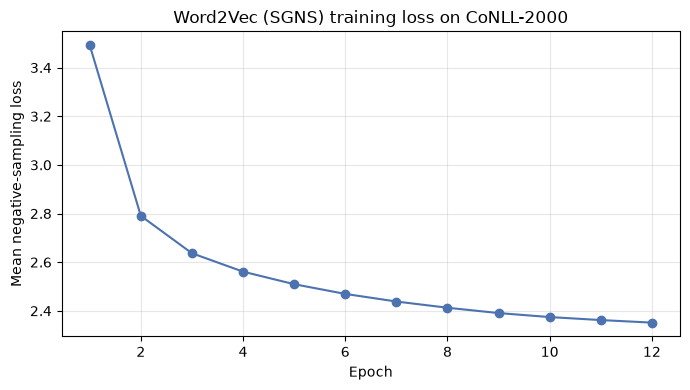

In [11]:
# 1. Numerical finite-difference gradient check of the manual backward pass
checker = Word2VecSGNS()
rel_err = checker.check_gradients()
print(f"Max relative gradient error vs finite differences: {rel_err:.2e}")
assert rel_err < 1e-5, "Analytical gradient mismatch!"

# 2. Tune Word2Vec hyperparameters on the validation set.
#    Selection criterion: validation POS-agreement@5 (same metric as PMI / TF-IDF).
#    The SGNS validation loss is reported too, but it is NOT used for selection: it sums K
#    negative-sample terms, so configs with different K are not comparable on it.
w2v_candidates = [
    dict(embedding_dim=50,  window_size=3, neg_samples=5,  lr=0.025, epochs=12, min_count=2),
    dict(embedding_dim=50,  window_size=3, neg_samples=10, lr=0.025, epochs=12, min_count=2),  # isolates K
    dict(embedding_dim=100, window_size=3, neg_samples=5,  lr=0.025, epochs=12, min_count=2),
    dict(embedding_dim=100, window_size=4, neg_samples=10, lr=0.025, epochs=15, min_count=2),
    dict(embedding_dim=150, window_size=4, neg_samples=10, lr=0.025, epochs=15, min_count=2),
]

print("\nTuning Word2Vec SGNS on validation data:")
best_w2v_cfg, best_w2v_score = None, -1.0
for cfg in w2v_candidates:
    t0 = time.time()
    m = Word2VecSGNS(**cfg, seed=SEED).fit(train_word_sents)
    vloss = m.validation_loss(val_word_sents)
    pos_ag = neighbor_pos_agreement(m, val_eval_words, k=5)
    print(
        f"  dim={cfg['embedding_dim']:>3}, win={cfg['window_size']}, neg={cfg['neg_samples']:>2}, "
        f"ep={cfg['epochs']:>2} -> val_loss={vloss:.4f}, POS-agree={pos_ag:.4f} ({time.time() - t0:.1f}s)"
    )
    if pos_ag > best_w2v_score:
        best_w2v_score = pos_ag
        best_w2v_cfg = cfg

print("\nSelected Word2Vec config:", best_w2v_cfg)
w2v_model = Word2VecSGNS(**best_w2v_cfg, seed=SEED).fit(train_word_sents, verbose=True)
print(f"Validation SGNS loss of final model: {w2v_model.validation_loss(val_word_sents):.4f}")

# 3. Training loss curve
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(w2v_model.loss_history) + 1), w2v_model.loss_history, marker="o", color="#4C72B0")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean negative-sampling loss")
ax.set_title("Word2Vec (SGNS) training loss on CoNLL-2000")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUTS / "word2vec_training_loss.png", dpi=120)
plt.show()

In [12]:
# The learned dense embeddings
E = w2v_model.embeddings
print("embedding matrix:", E.shape, E.dtype)
for w in ["the", "market", "rose"]:
    print(f"{w:>7}: {np.round(w2v_model.get_vector(w)[:8], 3)} ...")

embedding matrix: (7871, 50) float64
    the: [ 0.543  0.102 -0.176 -0.018 -0.36   0.306 -0.289  0.195] ...
 market: [ 0.198  0.863  0.07   0.727 -0.076  1.052  0.229  0.178] ...
   rose: [ 0.052  0.365  1.026 -0.086  1.13  -0.004  0.134 -0.159] ...


**Selected hyperparameters.** Each candidate is trained on the training split and scored on the validation split by
**POS-agreement@5**, the same intrinsic metric used for PMI and TF-IDF. The held-out SGNS loss is printed for
reference but is **not** used for selection. It sums $K$ negative-sample terms, so its value grows with $K$
(≈2.5 for $K=5$ vs ≈3.1–3.2 for $K=10$), and comparing configs with different $K$ on it would just favour small $K$.
The second candidate changes **only** $K$ (5 → 10, everything else fixed) so that the effect of $K$ can be seen
directly.

* **`dim = 50`** was selected (0.2872). On ~190k tokens there is not enough data to fill more dimensions:
  100 (same window/K/epochs) → 0.2782, and the 100- and 150-d configs with window 4 / $K=10$ → 0.2727 / 0.2702. The larger models also take 2–8× longer to train.
* **`K = 5`** negatives: on the controlled comparison, $K=10$ is slightly worse (0.2847 vs 0.2872) and 60% slower.
* **`window = 3`**: like PMI, a narrow window favours syntactic neighbours (the ±4 configs score lower).
* **`lr = 0.025`** with linear decay and **12 epochs**: the training-loss curve decreases monotonically, and the last
  epoch changes it by only ~0.01, so it has essentially converged.
* **`min_count = 2`** keeps the 7.9k-word vocabulary (96% of normalised tokens), as discussed in 1.1.

## 1.5 Comparison of the Three Representations

In [13]:
query_words = ["market", "prices", "bank", "said", "rose", "financial", "monday"]

for qw in query_words:
    pmi_n = [f"{w} ({s:.2f})" for w, s in pmi_model.most_similar(qw, top_k=5)]
    tfidf_n = [f"{w} ({s:.2f})" for w, s in tfidf_model.most_similar(qw, top_k=5)]
    w2v_n = [f"{w} ({s:.2f})" for w, s in w2v_model.most_similar(qw, top_k=5)]
    print(f"Query: '{qw}' (majority POS: {word_majority_tag.get(qw, '?')})")
    print(f"  PMI:      {', '.join(pmi_n)}")
    print(f"  TF-IDF:   {', '.join(tfidf_n)}")
    print(f"  Word2Vec: {', '.join(w2v_n)}\n")

# Quantitative comparison of dimensionality, sparsity, POS-agreement, and storage cost
models = {
    "PMI (Sparse)": pmi_model,
    "TF-IDF (Sparse)": tfidf_model,
    "Word2Vec (Dense)": w2v_model,
}

print(f"{'Representation':<18} {'Shape':<16} {'Sparsity':>10} {'Storage (KB)':>14} {'Val POS-Agree@5':>16}")
print("-" * 78)
for name, m in models.items():
    shape_str = f"{m.shape[0]} x {m.shape[1]}"
    kb = m.storage_bytes() / 1024.0
    pos_ag = neighbor_pos_agreement(m, val_eval_words, k=5)
    print(f"{name:<18} {shape_str:<16} {m.sparsity:>9.2%} {kb:>13.1f} {pos_ag:>16.4f}")

Query: 'market' (majority POS: NN)
  PMI:      stock (0.13), friday (0.13), plunge (0.12), arena (0.12), price (0.11)
  TF-IDF:   the (0.22), stock (0.19), in (0.15), to (0.14), and (0.13)
  Word2Vec: participants (0.87), gyrations (0.79), commentary (0.78), permitted (0.78), broad (0.78)

Query: 'prices' (majority POS: NNS)
  PMI:      oil (0.15), demand (0.13), sales (0.13), futures (0.12), stock (0.12)
  TF-IDF:   energy (0.18), wholesale (0.18), consumer (0.16), higher (0.15), oil (0.13)
  Word2Vec: pushed (0.81), selected (0.81), higher (0.78), push (0.78), lower (0.75)

Query: 'bank' (majority POS: NN)
  PMI:      loan (0.15), financing (0.14), federal (0.13), banking (0.13), loans (0.12)
  TF-IDF:   loans (0.20), m$ (0.19), basir (0.18), credit (0.18), paid-up (0.17)
  Word2Vec: financing (0.85), proposed (0.79), loan (0.79), contribution (0.77), carat (0.77)

Query: 'said' (majority POS: VBD)
  PMI:      mr. (0.20), chairman (0.19), spokesman (0.19), inc. (0.18), 's (0.18)
  TF

Query: 'monday' (majority POS: NNP)
  PMI:      friday (0.17), expiration (0.16), scheduled (0.16), arbitrage (0.15), tokyo (0.14)
  TF-IDF:   crew (0.19), bills (0.18), arbitrage (0.17), auction (0.16), stock-index (0.14)
  Word2Vec: session (0.89), friday (0.88), afternoon (0.88), crash (0.85), following (0.83)

Representation     Shape              Sparsity   Storage (KB)  Val POS-Agree@5
------------------------------------------------------------------------------


PMI (Sparse)       5630 x 5630         99.20%       23009.6           0.2650


TF-IDF (Sparse)    7871 x 8043         99.77%       13560.8           0.1788
Word2Vec (Dense)   7871 x 50            0.00%        3074.6           0.2872


**Semantic quality.**
* **Word2Vec** gives the most *substitutable* neighbours: *rose → climbed, jumped, slipped, decrease*; *monday →
  session, friday, afternoon*; *prices → pushed, higher, lower*. It also has the best validation POS-agreement (0.287). Its
  neighbours mostly share the query's grammatical role, which is what Part 3 needs. Some noise remains because the
  corpus is small (*rose → pharmaceutical*, *bank → carat*).
* **PMI** (±2 window) is a close second and is very clean for frequent words: *rose → jumped, gained, fell, climbed,
  dropped* is a perfect set of VBD neighbours. Its cosines are small (~0.1–0.25) because the vectors are very sparse,
  but the *ranking* is good.
* **TF-IDF** (sentence = document) captures **topic**, not role: *rose → `<NUM>`, 1\/4, from* (words that appear in
  stock-price sentences), *said → the, of, a, to*. It is the weakest for word similarity, and especially for POS.

**Sparsity, dimensionality, storage.**

| | dimensions | non-zeros | storage | similarity query |
|---|---|---|---|---|
| PMI | $|V|\times|V|$ = 5.6k × 5.6k | ~0.8% | largest (dict-of-dicts) | inverted index, cost grows with shared contexts |
| TF-IDF | $|V|\times|D|$ = 7.9k × 8.0k | ~0.2% | medium | inverted index over sentences |
| Word2Vec | $|V|\times d$ = 7.9k × 50 | 100% (dense) | smallest, fixed $|V|\cdot d\cdot 8$ B | one dense mat-vec |

The sparse matrices only store non-zeros, but Python dicts cost ~50–100 bytes per entry. As a result, the 0.8%-dense PMI
matrix (~255k non-zeros) still takes **~7.5×** the memory of the fully dense 50-d Word2Vec matrix (≈22.5 MB vs ≈3.0 MB). The
dimensionality of the sparse models grows with the data (vocabulary or number of sentences), while Word2Vec's $d$ is
a fixed choice. Word2Vec compresses the co-occurrence statistics into a low-rank space, which is why it generalises
better and is also the fastest to query (see the decoding times in Part 3).

# Part 2: Hidden Markov Model and Viterbi

## 2.0 Preprocessing for tagging
For POS tagging the tokens are kept **as-is** (no lowercasing, no number normalisation): capitalisation separates
`NNP` from `NN`, and the surface form of numbers and punctuation is itself strong evidence. Unknown words are
handled inside the model (2.1), not by rewriting the text.

In [14]:
train_vocab = Counter(w for s in train_sents for w, _ in s)
tag_counts = Counter(t for s in train_sents for _, t in s)
def oov_rate(sents):
    toks = [w for s in sents for w, _ in s]
    return sum(w not in train_vocab for w in toks) / len(toks)
print(f"tagset size: {len(tag_counts)}   training vocabulary: {len(train_vocab)} word types")
print(f"hapax legomena (count == 1): {sum(c == 1 for c in train_vocab.values())}")
print(f"OOV rate  val: {oov_rate(val_sents):.2%}   test: {oov_rate(test_sents):.2%}")
print("most frequent tags:", tag_counts.most_common(10))

tagset size: 44   training vocabulary: 18202 word types
hapax legomena (count == 1): 9111
OOV rate  val: 4.58%   test: 7.25%
most frequent tags: [('NN', 27214), ('IN', 20550), ('NNP', 17942), ('DT', 16524), ('NNS', 12291), ('JJ', 11752), (',', 9702), ('.', 7950), ('CD', 7548), ('VBD', 6086)]


## 2.1 Estimating the HMM

A first-order HMM with tags as hidden states:

$$P(t_{1:T}, w_{1:T}) = \pi(t_1)\prod_{i=2}^{T}A(t_{i-1}, t_i)\; P(\langle/s\rangle \mid t_T)\prod_{i=1}^{T}B(t_i, w_i)$$

All three parameter sets are maximum-likelihood counts with smoothing:

* **Initial / transition / end** — add-$k$ (Lidstone):
  $A(i,j) = \dfrac{c(i,j) + k_A}{c(i,\cdot) + c(i,\langle/s\rangle) + k_A (N+1)}$. The end-of-sentence event is part of each
  row, so every row of $[A \mid \text{end}]$ sums to 1. Smoothing guarantees no tag bigram has zero probability.
* **Emissions** — words seen more than `rare_threshold` times are the known vocabulary. All rarer training tokens are
  collapsed into one `<UNK>` symbol per tag, so $P(\langle UNK\rangle \mid t)$ learns *how open each tag is to new
  words* (high for `NN`, `NNP`, `JJ`, `CD`; ~0 for `DT`, `IN`, `CC`). Add-$k_B$ smoothing over vocabulary + `<UNK>`.

**Unknown words.** For a word without its own emission:

$$P(w\mid t) = P(\langle UNK\rangle\mid t)\cdot P(\text{sig}(w)\mid\langle UNK\rangle, t)$$

`sig(w)` is an orthographic/morphological signature (all-caps, capitalised mid-sentence vs. sentence-initial, digits,
hyphen, numeric pattern, common suffix like *-ing, -ed, -tion, -ly, -s*). Signature distributions are estimated from
the rare training tokens at three levels (full → shape only → plain UNK, add-$k_s$ smoothed) and the most specific level
observed in training is used. Additionally, an unseen word whose **lowercase form is known** (typically a
capitalised sentence-initial word) reuses the lowercase word's emissions.

In [15]:
"""First-order (bigram) HMM POS tagger estimated from tagged sentences.

Model
-----
    P(tags, words) = P(t_1) * prod_i P(t_i | t_{i-1}) * P(</s> | t_T) * prod_i P(w_i | t_i)

Smoothing
---------
* Initial / transition / end probabilities: add-k (Lidstone) smoothing, so every
  tag bigram has non-zero probability.
* Emissions: words seen more than ``rare_threshold`` times form the known
  vocabulary.  All rarer training tokens are collapsed into a single ``<UNK>``
  emission per tag, so P(<UNK> | t) learns how "open" each tag is (NN, JJ, NNP
  get a lot of mass; DT, IN, CC almost none).  Add-k smoothing is then applied
  over the known vocabulary + <UNK>.

Unknown words
-------------
For a word that is not in the known vocabulary:

    P(w | t) = P(<UNK> | t) * P(signature(w) | <UNK>, t)

where ``signature`` maps a word to a morphological/orthographic class
(capitalisation, digits, hyphens, common suffixes).  Signature distributions are
estimated from the rare training tokens at three granularities (full signature,
shape only, plain UNK) and the most specific level that was observed in training
is used.  Optionally, an unseen word whose lowercase form is known (e.g. a
capitalised sentence-initial word) reuses the lowercase word's emissions.

``unknown_log_emission`` is the single extension point used by the
embedding-assisted taggers in Part 3.
"""


import re
from collections import Counter, defaultdict

import numpy as np


UNK = "<UNK>"

# Ordered longest first so the most specific suffix wins.
SUFFIXES = (
    "ness", "ment", "tion", "sion", "ship", "ance", "ence", "able", "ible", "ical",
    "ious", "ward", "wise",
    "ful", "ous", "ive", "ize", "ise", "ity", "ing", "est", "ers", "ism", "ist",
    "ed", "er", "ly", "al", "ic", "es", "an", "en",
    "s", "y",
)
_SHAPE_NUMBER_RE = re.compile(r"^[+-]?[\d.,/:\-]*\d[\d.,/:\-]*%?$")


def word_shape(word: str, position: int) -> str:
    """Coarse orthographic class of a word."""
    if _SHAPE_NUMBER_RE.match(word):
        return "UNK-NUM"
    parts = ["UNK"]
    if word.isupper() and any(c.isalpha() for c in word):
        parts.append("ALLC")
    elif word[:1].isupper():
        parts.append("INITC" if position == 0 else "CAP")
    elif any(c.isupper() for c in word):
        parts.append("MIXC")
    if any(c.isdigit() for c in word):
        parts.append("DIG")
    if "-" in word:
        parts.append("DASH")
    return "-".join(parts)


def signature_levels(word: str, position: int) -> tuple[str, str, str]:
    """(full signature, shape-only signature, plain UNK) from specific to coarse."""
    shape = word_shape(word, position)
    if shape == "UNK-NUM":
        return shape, shape, UNK
    lower = word.lower()
    suffix = next((s for s in SUFFIXES if lower.endswith(s) and len(lower) > len(s) + 1), "")
    full = f"{shape}-{suffix}" if suffix else shape
    return full, shape, UNK


class HMMTagger:
    def __init__(
        self,
        rare_threshold: int = 1,
        trans_k: float = 0.1,
        emit_k: float = 0.01,
        sig_k: float = 0.1,
        lowercase_backoff: bool = True,
        use_signatures: bool = True,
    ):
        self.rare_threshold = rare_threshold
        self.trans_k = trans_k
        self.emit_k = emit_k
        self.sig_k = sig_k
        self.lowercase_backoff = lowercase_backoff
        self.use_signatures = use_signatures

    # ------------------------------------------------------------------ fit
    def fit(self, sentences: list[list[tuple[str, str]]]) -> "HMMTagger":
        self.word_counts = Counter(w for s in sentences for w, _ in s)
        self.tags = sorted({t for s in sentences for _, t in s})
        self.tag2idx = {t: i for i, t in enumerate(self.tags)}
        N = len(self.tags)

        known = sorted(w for w, c in self.word_counts.items() if c > self.rare_threshold)
        self.word2idx = {w: i for i, w in enumerate(known)}
        unk_col = len(known)
        V = len(known) + 1  # + <UNK>

        init = np.zeros(N)
        trans = np.zeros((N, N))
        end = np.zeros(N)
        emit = np.zeros((N, V))
        # signature counts per level: level -> sig -> (N,) counts
        sig_counts: list[dict[str, np.ndarray]] = [defaultdict(lambda: np.zeros(N)) for _ in range(3)]

        for sent in sentences:
            prev = None
            for pos, (w, t) in enumerate(sent):
                j = self.tag2idx[t]
                if prev is None:
                    init[j] += 1
                else:
                    trans[prev, j] += 1
                col = self.word2idx.get(w)
                if col is None:
                    emit[j, unk_col] += 1
                    for lvl, sig in enumerate(signature_levels(w, pos)):
                        sig_counts[lvl][sig][j] += 1
                else:
                    emit[j, col] += 1
                prev = j
            if prev is not None:
                end[prev] += 1

        k = self.trans_k
        self.log_pi = np.log((init + k) / (init.sum() + k * N))
        # transitions out of tag i also include the end-of-sentence event
        out_totals = trans.sum(axis=1) + end
        self.log_A = np.log((trans + k) / (out_totals[:, None] + k * (N + 1)))
        self.log_end = np.log((end + k) / (out_totals + k * (N + 1)))

        ke = self.emit_k
        self.log_B = np.log((emit + ke) / (emit.sum(axis=1, keepdims=True) + ke * V))
        self.log_p_unk = self.log_B[:, unk_col]

        # P(sig | <UNK>, tag) per level, add-k smoothed within each level
        rare_per_tag = emit[:, unk_col]
        self.log_sig: list[dict[str, np.ndarray]] = []
        for lvl_counts in sig_counts:
            S = len(lvl_counts)
            denom = rare_per_tag + self.sig_k * S
            self.log_sig.append({
                sig: np.log((c + self.sig_k) / denom) for sig, c in lvl_counts.items()
            })
        return self

    # ------------------------------------------------------------ emissions
    def is_known(self, word: str) -> bool:
        """Word has its own emission column (seen > rare_threshold times)."""
        return word in self.word2idx

    def is_oov(self, word: str) -> bool:
        """Word never appeared in the training data (used for evaluation)."""
        return word not in self.word_counts

    def signature_log_emission(self, word: str, position: int) -> np.ndarray:
        """log P(<UNK>|t) + log P(signature(w) | <UNK>, t) using the most specific seen level."""
        if not self.use_signatures:
            return self.log_p_unk
        for lvl, sig in enumerate(signature_levels(word, position)):
            table = self.log_sig[lvl]
            if sig in table:
                return self.log_p_unk + table[sig]
        return self.log_p_unk  # unreachable in practice: UNK level always exists

    def unknown_log_emission(self, words: list[str], position: int) -> np.ndarray:
        """Emission scores (N,) for a word without its own emission column.

        Override this in subclasses to plug in other unknown-word strategies.
        """
        word = words[position]
        if self.lowercase_backoff:
            col = self.word2idx.get(word.lower())
            if col is not None:
                return self.log_B[:, col]
        return self.signature_log_emission(word, position)

    def emission_matrix(self, words: list[str]) -> np.ndarray:
        T, N = len(words), len(self.tags)
        out = np.empty((T, N))
        for i, w in enumerate(words):
            col = self.word2idx.get(w)
            out[i] = self.log_B[:, col] if col is not None else self.unknown_log_emission(words, i)
        return out

    # ------------------------------------------------------------- decoding
    def predict(self, words: list[str]) -> list[str]:
        path, _ = viterbi(self.log_pi, self.log_A, self.emission_matrix(words), self.log_end)
        return [self.tags[j] for j in path]

    def predict_many(self, sentences: list[list[str]]) -> list[list[str]]:
        return [self.predict(ws) for ws in sentences]

In [16]:
for w, pos in [("reorganizing", 3), ("Mitsubishi", 4), ("Corp.", 5), ("1,234.5", 2), ("quickly", 1),
               ("anti-takeover", 6), ("IBM", 3), ("Yesterday", 0), ("transactions", 7)]:
    print(f"{w:<15} -> {signature_levels(w, pos)}")

reorganizing    -> ('UNK-ing', 'UNK', '<UNK>')
Mitsubishi      -> ('UNK-CAP', 'UNK-CAP', '<UNK>')
Corp.           -> ('UNK-CAP', 'UNK-CAP', '<UNK>')
1,234.5         -> ('UNK-NUM', 'UNK-NUM', '<UNK>')
quickly         -> ('UNK-ly', 'UNK', '<UNK>')
anti-takeover   -> ('UNK-DASH-er', 'UNK-DASH', '<UNK>')
IBM             -> ('UNK-ALLC', 'UNK-ALLC', '<UNK>')
Yesterday       -> ('UNK-INITC-y', 'UNK-INITC', '<UNK>')
transactions    -> ('UNK-s', 'UNK', '<UNK>')


## 2.2 Viterbi decoding

Dynamic programming over tags: $\delta_t(j) = \max_i[\delta_{t-1}(i) + \log A(i,j)] + \log B(j, w_t)$ with
back-pointers. Everything is in **log space**: a product of hundreds of probabilities underflows float64, while a sum
of log-probabilities does not, and `argmax` is unchanged because log is monotonic. The inner max over previous tags is
vectorised as an $N\times N$ NumPy operation, so decoding is $O(TN^2)$.

In [17]:
"""Log-space Viterbi decoding implemented with NumPy."""


import numpy as np


def viterbi(
    log_pi: np.ndarray,
    log_A: np.ndarray,
    log_emit: np.ndarray,
    log_end: np.ndarray | None = None,
) -> tuple[list[int], float]:
    """Most likely state sequence for one observation sequence.

    Args:
        log_pi:   (N,)   log P(t_1 = j)
        log_A:    (N, N) log P(t_i = j | t_{i-1} = i)
        log_emit: (T, N) log P(w_t | tag j) for every position of the sentence
        log_end:  (N,)   optional log P(</s> | t_T = j)

    Working entirely with log-probabilities turns products into sums, so long
    sentences never underflow the way raw probability products would.

    Returns:
        (best_path as list of state indices, its log-probability)
    """
    T, N = log_emit.shape
    if T == 0:
        return [], 0.0

    delta = log_pi + log_emit[0]                      # (N,)
    backptr = np.zeros((T, N), dtype=np.int32)

    for t in range(1, T):
        # scores[i, j] = best score ending in i at t-1, then transition i -> j
        scores = delta[:, None] + log_A               # (N, N)
        backptr[t] = np.argmax(scores, axis=0)
        delta = scores[backptr[t], np.arange(N)] + log_emit[t]

    if log_end is not None:
        delta = delta + log_end

    last = int(np.argmax(delta))
    best_score = float(delta[last])

    path = [last]
    for t in range(T - 1, 0, -1):
        path.append(int(backptr[t, path[-1]]))
    path.reverse()
    return path, best_score

**Sanity check** — on short random sentences, Viterbi must match exhaustive search over all $N^T$ tag sequences.

In [18]:
def brute_force(log_pi, log_A, log_emit, log_end):
    T, N = log_emit.shape
    best, best_path = -np.inf, None
    for path in itertools.product(range(N), repeat=T):
        s = log_pi[path[0]] + log_emit[0, path[0]] + log_end[path[-1]]
        s += sum(log_A[path[t-1], path[t]] + log_emit[t, path[t]] for t in range(1, T))
        if s > best:
            best, best_path = s, list(path)
    return best_path, best

rng = np.random.default_rng(0)
for trial in range(5):
    N, T = 5, rng.integers(1, 6)
    lp = np.log(rng.dirichlet(np.ones(N)))
    lA = np.log(rng.dirichlet(np.ones(N), size=N))
    lE = np.log(rng.random((T, N)))
    le = np.log(rng.random(N))
    p1, s1 = viterbi(lp, lA, lE, le)
    p2, s2 = brute_force(lp, lA, lE, le)
    assert p1 == p2 and np.isclose(s1, s2), (p1, p2)
print("Viterbi matches brute force on all trials.")

Viterbi matches brute force on all trials.


### Evaluation utilities
Token accuracy, per-tag precision / recall / F1, and macro and support-weighted averages, computed separately on all
tokens, **known** tokens and **unknown** tokens (word never seen in training).

In [19]:
"""Token-level POS tagging metrics implemented with NumPy."""


from collections import Counter
from collections.abc import Callable

import numpy as np


def per_tag_prf(gold: list[str], pred: list[str]) -> dict[str, dict[str, float]]:
    """Precision, recall, F1 and support for every tag seen in gold or pred."""
    tags = sorted(set(gold) | set(pred))
    tp, fp, fn = Counter(), Counter(), Counter()
    for g, p in zip(gold, pred):
        if g == p:
            tp[g] += 1
        else:
            fp[p] += 1
            fn[g] += 1
    out = {}
    for t in tags:
        prec = tp[t] / (tp[t] + fp[t]) if tp[t] + fp[t] else 0.0
        rec = tp[t] / (tp[t] + fn[t]) if tp[t] + fn[t] else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        out[t] = {"precision": prec, "recall": rec, "f1": f1, "support": tp[t] + fn[t]}
    return out


def summarize(gold: list[str], pred: list[str]) -> dict[str, float]:
    """Accuracy plus macro- and support-weighted P/R/F1.

    For single-label token classification micro-P = micro-R = micro-F1 = accuracy,
    so macro (every tag equal) and weighted (by gold support) averages are reported.
    Macro averages are taken over tags with gold support > 0.
    """
    n = len(gold)
    if n == 0:
        return {"tokens": 0}
    per_tag = per_tag_prf(gold, pred)
    supported = {t: m for t, m in per_tag.items() if m["support"] > 0}
    sup = np.array([m["support"] for m in supported.values()], dtype=float)
    res = {"tokens": n, "accuracy": float(np.mean(np.array(gold) == np.array(pred)))}
    for key in ("precision", "recall", "f1"):
        vals = np.array([m[key] for m in supported.values()])
        res[f"macro_{key}"] = float(vals.mean())
        res[f"weighted_{key}"] = float((vals * sup).sum() / sup.sum())
    return res


def evaluate(
    gold_sents: list[list[str]],
    pred_sents: list[list[str]],
    word_sents: list[list[str]],
    is_oov: Callable[[str], bool],
) -> dict[str, dict[str, float]]:
    """Metrics on all tokens, in-vocabulary tokens and out-of-vocabulary tokens."""
    gold = [t for s in gold_sents for t in s]
    pred = [t for s in pred_sents for t in s]
    oov = [is_oov(w) for s in word_sents for w in s]
    subsets = {"all": [True] * len(gold), "known": [not o for o in oov], "unknown": oov}
    return {
        name: summarize([g for g, m in zip(gold, mask) if m], [p for p, m in zip(pred, mask) if m])
        for name, mask in subsets.items()
    }


def format_results(results: dict[str, dict[str, dict[str, float]]]) -> str:
    """Pretty table: rows = system/subset, columns = metrics."""
    cols = ["tokens", "accuracy", "macro_precision", "macro_recall", "macro_f1",
            "weighted_precision", "weighted_recall", "weighted_f1"]
    short = ["tokens", "acc", "macroP", "macroR", "macroF1", "wP", "wR", "wF1"]
    lines = [f"{'system':<28}{'subset':<9}" + "".join(f"{c:>9}" for c in short)]
    lines.append("-" * len(lines[0]))
    for system, by_subset in results.items():
        for subset, m in by_subset.items():
            row = f"{system:<28}{subset:<9}{m['tokens']:>9}"
            row += "".join(f"{m[c]:>9.4f}" for c in cols[1:])
            lines.append(row)
    return "\n".join(lines)


def confusion_matrix(gold: list[str], pred: list[str], tags: list[str]) -> np.ndarray:
    idx = {t: i for i, t in enumerate(tags)}
    cm = np.zeros((len(tags), len(tags)), dtype=int)
    for g, p in zip(gold, pred):
        cm[idx[g], idx[p]] += 1
    return cm


def top_confusions(gold: list[str], pred: list[str], k: int = 10) -> list[tuple[str, str, int]]:
    c = Counter((g, p) for g, p in zip(gold, pred) if g != p)
    return [(g, p, n) for (g, p), n in c.most_common(k)]

## 2.3 Hyperparameter tuning on the validation set

Grid over the rare-word threshold, transition $k_A$, emission $k_B$ and signature $k_s$ smoothing constants, with and
without lowercase back-off. Selection criterion: overall validation token accuracy (ties broken by unknown-word accuracy).

In [20]:
val_words = [words_of(s) for s in val_sents]
val_gold = [tags_of(s) for s in val_sents]

grid = dict(rare_threshold=[1, 2, 3], trans_k=[0.01, 0.1, 1.0], emit_k=[0.001, 0.01, 0.1],
            sig_k=[0.1, 1.0], lowercase_backoff=[True, False])
keys = list(grid)
rows = []
t0 = time.time()
for values in itertools.product(*grid.values()):
    params = dict(zip(keys, values))
    m = HMMTagger(**params).fit(train_sents)
    r = evaluate(val_gold, m.predict_many(val_words), val_words, m.is_oov)
    rows.append((r["all"]["accuracy"], r["unknown"]["accuracy"], params))
print(f"{len(rows)} configurations in {time.time() - t0:.1f}s")

rows.sort(key=lambda x: (x[0], x[1]), reverse=True)
print(f"{'val acc':>8} {'unk acc':>8}  params")
for acc, unk, p in rows[:10]:
    print(f"{acc:8.4f} {unk:8.4f}  {p}")
print("...worst:", f"{rows[-1][0]:.4f}", rows[-1][2])
best_params = rows[0][2]
print("\nselected:", best_params)

108 configurations in 55.1s
 val acc  unk acc  params
  0.9719   0.8456  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': True}
  0.9719   0.8456  {'rare_threshold': 1, 'trans_k': 0.1, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': True}
  0.9719   0.8403  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': False}
  0.9718   0.8445  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 1.0, 'lowercase_backoff': True}
  0.9718   0.8445  {'rare_threshold': 1, 'trans_k': 0.1, 'emit_k': 0.001, 'sig_k': 1.0, 'lowercase_backoff': True}
  0.9718   0.8403  {'rare_threshold': 1, 'trans_k': 0.1, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': False}
  0.9716   0.8477  {'rare_threshold': 1, 'trans_k': 1.0, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': True}
  0.9716   0.8393  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 1.0, 'lowercase_backoff': False}
  0.9716   0.8435  

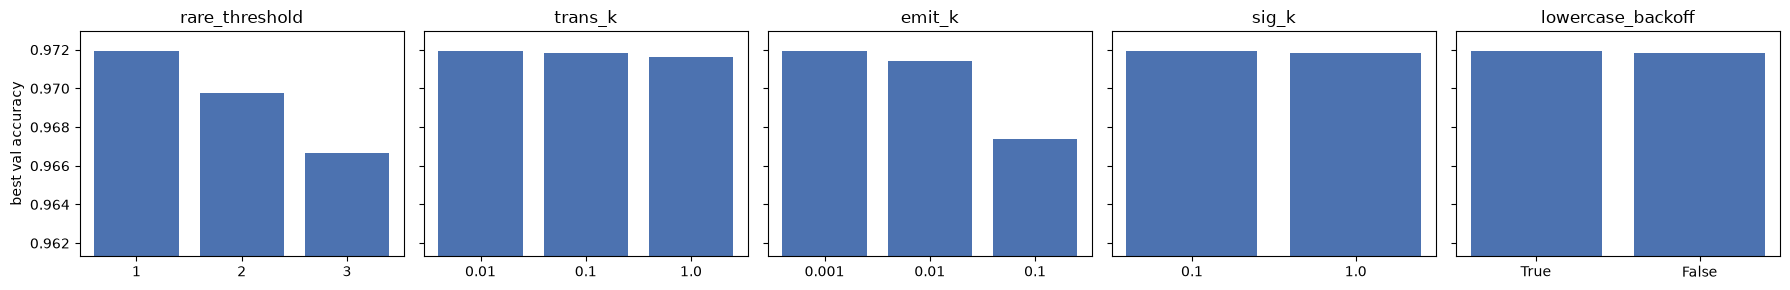

In [21]:
# Effect of each hyperparameter: best validation accuracy reachable with each value
fig, axes = plt.subplots(1, len(keys), figsize=(18, 3), sharey=True)
for ax, k in zip(axes, keys):
    vals = grid[k]
    best = [max(a for a, _, p in rows if p[k] == v) for v in vals]
    ax.bar([str(v) for v in vals], best, color="#4C72B0")
    ax.set_title(k); ax.set_ylim(min(a for a, _, _ in rows) - 0.002, max(best) + 0.001)
axes[0].set_ylabel("best val accuracy")
plt.tight_layout(); plt.savefig(OUTPUTS / "hmm_tuning.png", dpi=120); plt.show()

**Ablation of the unknown-word strategy** (validation set, other hyperparameters fixed at the selected values):

In [22]:
ablations = {
    "plain <UNK> only":           dict(best_params, use_signatures=False, lowercase_backoff=False),
    "+ signatures":               dict(best_params, use_signatures=True,  lowercase_backoff=False),
    "+ signatures + lowercase":   dict(best_params, use_signatures=True,  lowercase_backoff=True),
}
abl_results = {}
for name, p in ablations.items():
    m = HMMTagger(**p).fit(train_sents)
    abl_results[name] = evaluate(val_gold, m.predict_many(val_words), val_words, m.is_oov)
print(format_results(abl_results))

system                      subset      tokens      acc   macroP   macroR  macroF1       wP       wR      wF1
-------------------------------------------------------------------------------------------------------------
plain <UNK> only            all          20784   0.9461   0.9340   0.9461   0.9336   0.9473   0.9461   0.9462
plain <UNK> only            known        19832   0.9669   0.9514   0.9615   0.9517   0.9676   0.9669   0.9670
plain <UNK> only            unknown        952   0.5126   0.2708   0.2318   0.2405   0.4938   0.5126   0.4881
+ signatures                all          20784   0.9719   0.9531   0.9645   0.9543   0.9723   0.9719   0.9719
+ signatures                known        19832   0.9782   0.9575   0.9711   0.9599   0.9787   0.9782   0.9783
+ signatures                unknown        952   0.8403   0.5644   0.5386   0.5490   0.8335   0.8403   0.8340
+ signatures + lowercase    all          20784   0.9719   0.9480   0.9654   0.9517   0.9725   0.9719   0.9721
+ signatur

## 2.4 Final evaluation on the test set

The model is refit on the training split with the selected hyperparameters (the same training data the embeddings in
Part 1 use, so Part 3 compares like with like) and evaluated **once** on the untouched test partition.

*Unknown* = test token never seen in training; *known* = everything else. Because each token gets exactly one tag,
micro-averaged P/R/F1 equal accuracy, so macro (every tag equal) and support-weighted averages are reported too.

In [23]:
hmm = HMMTagger(**best_params).fit(train_sents)
test_words = [words_of(s) for s in test_sents]
test_gold = [tags_of(s) for s in test_sents]
t0 = time.time()
test_pred = hmm.predict_many(test_words)
print(f"decoded {len(test_sents)} sentences in {time.time() - t0:.2f}s")

baseline_results = evaluate(test_gold, test_pred, test_words, hmm.is_oov)
print(format_results({"baseline HMM": baseline_results}))

decoded 2013 sentences in 0.40s
system                      subset      tokens      acc   macroP   macroR  macroF1       wP       wR      wF1
-------------------------------------------------------------------------------------------------------------
baseline HMM                all          47377   0.9662   0.9255   0.9312   0.9224   0.9669   0.9662   0.9663
baseline HMM                known        43944   0.9768   0.9358   0.9565   0.9397   0.9772   0.9768   0.9769
baseline HMM                unknown       3433   0.8302   0.6807   0.6537   0.6532   0.8402   0.8302   0.8296


In [24]:
flat_gold = [t for s in test_gold for t in s]
flat_pred = [t for s in test_pred for t in s]
flat_words = [w for s in test_words for w in s]
flat_oov = [hmm.is_oov(w) for w in flat_words]

per_tag = per_tag_prf(flat_gold, flat_pred)
unk_tag = per_tag_prf([g for g, o in zip(flat_gold, flat_oov) if o], [p for p, o in zip(flat_pred, flat_oov) if o])
print(f"{'tag':<6}{'support':>8}{'P':>8}{'R':>8}{'F1':>8}   | unknown: {'support':>7}{'P':>8}{'R':>8}{'F1':>8}")
for t, m in sorted(per_tag.items(), key=lambda x: -x[1]["support"]):
    if m["support"] == 0: continue
    u = unk_tag.get(t)
    us = f"{u['support']:>7}{u['precision']:>8.3f}{u['recall']:>8.3f}{u['f1']:>8.3f}" if u and u["support"] else ""
    print(f"{t:<6}{m['support']:>8}{m['precision']:>8.3f}{m['recall']:>8.3f}{m['f1']:>8.3f}   |          {us}")

tag    support       P       R      F1   | unknown: support       P       R      F1
NN        6642   0.953   0.946   0.949   |              617   0.775   0.702   0.736
IN        5071   0.985   0.987   0.986   |                5   0.667   0.800   0.727
NNP       4806   0.977   0.952   0.964   |             1127   0.951   0.882   0.915
DT        4020   0.996   0.995   0.995   |                1   1.000   1.000   1.000
NNS       3034   0.961   0.980   0.970   |              386   0.827   0.904   0.864
JJ        2964   0.883   0.933   0.907   |              439   0.626   0.822   0.711
,         2390   1.000   1.000   1.000   |          
.         1975   0.999   1.000   1.000   |          
CD        1918   0.994   0.997   0.996   |              317   0.972   0.991   0.981
VBD       1679   0.956   0.930   0.943   |               51   0.750   0.647   0.695
RB        1354   0.945   0.932   0.939   |               63   0.891   0.905   0.898
VB        1269   0.924   0.930   0.927   |            

Most frequent confusions (gold -> predicted), all tokens:
     NN -> JJ    207
    NNP -> NN    105
    VBD -> VBN   104
     JJ -> NN    93
    VBN -> VBD   68
    NNP -> JJ    63
     RB -> IN    54
    VBZ -> NNS   51
    VBP -> VB    40
     NN -> VB    35

Most frequent confusions, unknown tokens:
     NN -> JJ    127
    NNP -> NN    57
     JJ -> NN    49
    NNP -> JJ    28
    VBN -> JJ    25
    NNP -> NNS   24
   NNPS -> NNS   18
   NNPS -> NNP   17
     NN -> VBG   16
    NNS -> JJ    15


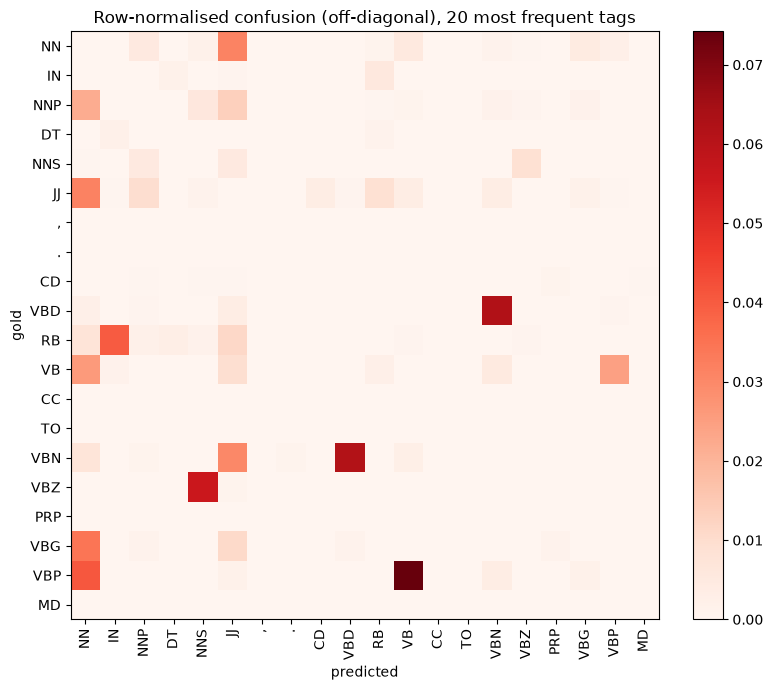

In [25]:
print("Most frequent confusions (gold -> predicted), all tokens:")
for g, p, n in top_confusions(flat_gold, flat_pred, 10):
    print(f"  {g:>5} -> {p:<5} {n}")
print("\nMost frequent confusions, unknown tokens:")
unk_pairs = [(g, p) for g, p, o in zip(flat_gold, flat_pred, flat_oov) if o]
for g, p, n in top_confusions(*zip(*unk_pairs), 10):
    print(f"  {g:>5} -> {p:<5} {n}")

tags_shown = [t for t, _ in Counter(flat_gold).most_common(20)]
mask = [g in tags_shown and p in tags_shown for g, p in zip(flat_gold, flat_pred)]
cm = confusion_matrix([g for g, m in zip(flat_gold, mask) if m], [p for p, m in zip(flat_pred, mask) if m], tags_shown)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
off = cm_norm.copy(); np.fill_diagonal(off, 0)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(off, cmap="Reds")
ax.set_xticks(range(len(tags_shown)), tags_shown, rotation=90); ax.set_yticks(range(len(tags_shown)), tags_shown)
ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title("Row-normalised confusion (off-diagonal), 20 most frequent tags")
fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(OUTPUTS / "hmm_confusion.png", dpi=120); plt.show()

In [26]:
# A few unknown-word errors in context
shown = 0
for ws, gs, ps in zip(test_words, test_gold, test_pred):
    for i, (w, g, p) in enumerate(zip(ws, gs, ps)):
        if hmm.is_oov(w) and g != p and shown < 12:
            ctx = " ".join(ws[max(0, i-3):i]) + f" [{w}] " + " ".join(ws[i+1:i+4])
            print(f"{g:>5} -> {p:<5} {signature_levels(w, i)[0]:<20} {ctx}")
            shown += 1

   NN -> JJ    UNK                  pressure floor , [torque] box , fixed
   JJ -> NN    UNK                  wings and an [aft] keel beam .
   NN -> JJ    UNK-DASH-ment        real-estate investment and [asset-management] duties , Mr.
   NN -> VBG   UNK-ing              in expected mortgage [servicing] fees , reflecting
   VB -> NN    UNK-INITC             [Look] at what happened
   NN -> JJ    UNK-DASH-tion        Tiger with combined [stock-option] gains of about
   NN -> JJ    UNK                  their spouses , [lifetime] access to the
  NNP -> JJ    UNK-CAP-ly           access to the [Friendly] Skies -- free
 NNPS -> NNS   UNK-CAP-es           to the Friendly [Skies] -- free first-class
  NNP -> NNS   UNK-CAP-es           US [Facilities] Corp. said Robert
 NNPS -> NNS   UNK-CAP-es           statement , US [Facilities] said Mr. Percival
 NNPS -> NNS   UNK-CAP-es           director , US [Facilities] said , but


## 2.5 Discussion

**Results.** The tuned HMM reaches **96.6% token accuracy** on the test set (weighted F1 0.966). On the
in-vocabulary tokens it reaches 97.7%, and on the 3,433 unknown tokens (7.3% of the test set) it reaches **83.0%**. The
test OOV rate is higher than the validation OOV rate (7.3% vs 4.6%), because validation sentences come from the same
sections as training. This is why test accuracy is a bit lower than validation accuracy (97.2%).

**Hyperparameters.**
* `rare_threshold = 1`: only hapaxes feed `<UNK>`. Higher thresholds strip real emission evidence from frequent-ish words, and
  the hapaxes alone already represent unseen words well (in the spirit of Good–Turing).
* `emit_k = 0.001`: this mattered most. A large emission $k$ gives closed-class tags (DT, IN) a noticeable probability for
  every word, which makes the tagger worse at telling tags apart.
* `trans_k`: barely matters (0.01 and 0.1 tie), because with ~190k tokens almost every useful tag bigram is observed.
* Lowercase back-off: leaves overall accuracy unchanged but raises unknown-word accuracy (84.0 → 84.6%) and unknown
  macro-F1 (0.55 → 0.71) on validation. It was chosen by the tie-break.

**Unknown-word handling is the main lever.** With a plain `<UNK>` emission, unknown-word accuracy is only 51%, because
every unseen word gets pushed toward the most "open" tag. Adding signatures raises it to 84% and also improves the
*known* words (96.7 → 97.8%), since a bad guess on an unknown word spreads through the transitions to its neighbours.

**Remaining errors** are the classic hard cases for an HMM:
* NN ↔ JJ for prenominal modifiers such as *torque box* and *lifetime access*. The left context (DT/JJ) fits both tags,
  and a bigram model cannot see the head noun that follows.
* VBD ↔ VBN (*-ed* forms). Telling them apart needs an auxiliary that may be several words back.
* NNPS → NNS / NNP for capitalised plurals like *US Facilities*. NNPS is rare, so its unknown recall is only 17%.
* NNP → NN/JJ for unseen capitalised words whose capitalisation signal is weak or misleading.

Signatures only look at the surface form of a word. They cannot tell that *torque* behaves like *engine* or
*pressure*, and that kind of distributional similarity is exactly what Part 3 adds with the embeddings.

# Part 3: Embedding-Assisted HMM

## 3.1 Strategy and Implementation

**Unknown-word handling with embeddings.**  When the HMM meets a word without its own emission column it falls back to morphological signatures (Part 2).  Here we enrich that estimate with word-embedding similarity:

1. **Retrieve neighbours** — look up the OOV word in the embedding vocabulary.  If it is present, call `most_similar(word, k)`.  If not (true OOV), form a *context bag* from the surrounding ±3 tokens and call `most_similar_from_context(context_words, k)`.
2. **Average HMM emissions** — keep only neighbours that are *known words* in the HMM (they have a full emission column).  Compute a similarity-weighted average of their emission probability vectors $P(\cdot|t)$.
3. **Interpolate with baseline** — mix the embedding-derived emission with the morphological baseline using weight $\alpha$:

$$\log P_{\text{emb}}(w|t) = \log\!\left[(1-\alpha)\,\exp(\text{baseline}(w,t)) + \alpha\,\exp(\overline{P}_{\text{sim}}(w,t))\right]$$

This is computed in log-space with a log-sum-exp for numerical stability.  The same `EmbeddingAssistedHMM` class works with PMI, TF-IDF, and Word2Vec because all three expose the same `most_similar` / `most_similar_from_context` interface.

In [27]:
import numpy as np


def _logsumexp2(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    m = np.maximum(a, b)
    return m + np.log(np.exp(a - m) + np.exp(b - m))


class EmbeddingAssistedHMM(HMMTagger):
    def __init__(
        self,
        embedding_model=None,
        embed_weight: float = 0.5,
        top_k: int = 10,
        ctx_window: int = 3,
        **hmm_kwargs,
    ):
        super().__init__(**hmm_kwargs)
        self.embedding_model = embedding_model
        self.embed_weight = embed_weight
        self.top_k = top_k
        self.ctx_window = ctx_window

    def _embedding_emission(self, words: list[str], position: int) -> np.ndarray | None:
        word = words[position]
        em = self.embedding_model

        # --- Try to find neighbours via word similarity first
        neighbours = em.most_similar(word, top_k=self.top_k)

        # --- Fallback: query by context if the word is not in embed vocab
        if not neighbours:
            left = max(0, position - self.ctx_window)
            right = min(len(words), position + self.ctx_window + 1)
            ctx = [w for i, w in enumerate(words[left:right], start=left) if i != position]
            neighbours = em.most_similar_from_context(ctx, top_k=self.top_k)

        if not neighbours:
            return None

        # Keep only neighbours that exist as *known* words in the HMM
        # (i.e. have their own emission column).
        weighted: list[tuple[np.ndarray, float]] = []
        for nbr_word, sim in neighbours:
            if sim <= 0.0:
                continue
            col = self.word2idx.get(nbr_word)
            if col is None:
                col = self.word2idx.get(nbr_word.lower())
            if col is not None:
                weighted.append((self.log_B[:, col], sim))

        if not weighted:
            return None

        total_weight = sum(s for _, s in weighted)
        avg_emit = sum(s / total_weight * np.exp(logb) for logb, s in weighted)
        avg_emit = np.maximum(avg_emit, 1e-300)  # guard underflow
        return np.log(avg_emit)

    def unknown_log_emission(self, words: list[str], position: int) -> np.ndarray:
        baseline = super().unknown_log_emission(words, position)

        if self.embedding_model is None or self.embed_weight <= 0.0:
            return baseline

        emb_logp = self._embedding_emission(words, position)
        if emb_logp is None:
            return baseline

        alpha = self.embed_weight
        # log( (1-α)*exp(baseline) + α*exp(emb_logp) )
        return _logsumexp2(
            np.log(1.0 - alpha) + baseline,
            np.log(alpha) + emb_logp,
        )

**How often can each representation see an unknown word directly?** The embeddings are trained on the same training
split as the HMM. A test word that the HMM has never seen can therefore only be in an embedding vocabulary through
normalisation (lowercasing, `<NUM>`). All other unknown words must use the **context-based** fallback.

In [28]:
test_words = [words_of(s) for s in test_sents]
test_gold = [tags_of(s) for s in test_sents]
unk_test_tokens = [w for ws in test_words for w in ws if w not in train_vocab]
for name, m in [("PMI", pmi_model), ("TF-IDF", tfidf_model), ("Word2Vec", w2v_model)]:
    direct = sum(m._resolve_id(w) is not None for w in unk_test_tokens)
    print(f"{name:<9} unknown test tokens with a direct vector: {direct:>4}/{len(unk_test_tokens)} "
          f"({direct / len(unk_test_tokens):.1%})  -> rest use the context fallback")

PMI       unknown test tokens with a direct vector:  474/3433 (13.8%)  -> rest use the context fallback
TF-IDF    unknown test tokens with a direct vector:  527/3433 (15.4%)  -> rest use the context fallback
Word2Vec  unknown test tokens with a direct vector:  527/3433 (15.4%)  -> rest use the context fallback


## 3.2 Tuning the interpolation weight and the four-system comparison

$\alpha$ is tuned separately for each representation on the **validation** set (criterion: unknown-word accuracy).
The final systems are then evaluated once on the test set.

In [29]:
val_words_p3 = [words_of(s) for s in val_sents]
val_gold_p3  = [tags_of(s)  for s in val_sents]

alpha_grid = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

def tune_alpha(emb_model, label):
    best_alpha, best_unk_acc = 0.3, -1.0
    for alpha in alpha_grid:
        m = EmbeddingAssistedHMM(
            embedding_model=emb_model, embed_weight=alpha, top_k=10,
            **best_params
        ).fit(train_sents)
        preds = m.predict_many(val_words_p3)
        res = evaluate(val_gold_p3, preds, val_words_p3, m.is_oov)
        unk_acc = res['unknown'].get('accuracy', 0.0)
        all_acc = res['all'].get('accuracy', 0.0)
        print(f"  {label}: alpha={alpha:.1f} -> unknown-acc={unk_acc:.4f}  all-acc={all_acc:.4f}")
        if unk_acc > best_unk_acc:
            best_unk_acc = unk_acc
            best_alpha   = alpha
    print(f"  => best alpha for {label}: {best_alpha}  (unknown-acc={best_unk_acc:.4f})\n")
    return best_alpha

print("=== Tuning embed_weight (alpha) on validation set ===\n")
print("PMI:")
best_alpha_pmi   = tune_alpha(pmi_model,   "PMI")
print("TF-IDF:")
best_alpha_tfidf = tune_alpha(tfidf_model, "TF-IDF")
print("Word2Vec:")
best_alpha_w2v   = tune_alpha(w2v_model,   "Word2Vec")

=== Tuning embed_weight (alpha) on validation set ===

PMI:


  PMI: alpha=0.1 -> unknown-acc=0.8424  all-acc=0.9718


  PMI: alpha=0.2 -> unknown-acc=0.8393  all-acc=0.9716


  PMI: alpha=0.3 -> unknown-acc=0.8361  all-acc=0.9713


  PMI: alpha=0.4 -> unknown-acc=0.8277  all-acc=0.9705


  PMI: alpha=0.5 -> unknown-acc=0.8267  all-acc=0.9704


... (12 outputs left out)

  Word2Vec: alpha=0.4 -> unknown-acc=0.8424  all-acc=0.9714


  Word2Vec: alpha=0.5 -> unknown-acc=0.8372  all-acc=0.9710


  Word2Vec: alpha=0.6 -> unknown-acc=0.8330  all-acc=0.9706


  Word2Vec: alpha=0.7 -> unknown-acc=0.8267  all-acc=0.9702
  => best alpha for Word2Vec: 0.2  (unknown-acc=0.8466)



In [30]:
pmi_hmm = EmbeddingAssistedHMM(
    embedding_model=pmi_model, embed_weight=best_alpha_pmi, top_k=10,
    **best_params
).fit(train_sents)

tfidf_hmm = EmbeddingAssistedHMM(
    embedding_model=tfidf_model, embed_weight=best_alpha_tfidf, top_k=10,
    **best_params
).fit(train_sents)

w2v_hmm = EmbeddingAssistedHMM(
    embedding_model=w2v_model, embed_weight=best_alpha_w2v, top_k=10,
    **best_params
).fit(train_sents)

# --- Run test-set predictions ---
t0 = time.time()
pmi_pred   = pmi_hmm.predict_many(test_words)
t1 = time.time()
tfidf_pred = tfidf_hmm.predict_many(test_words)
t2 = time.time()
w2v_pred   = w2v_hmm.predict_many(test_words)
t3 = time.time()

print(f"Decoding times: PMI {t1-t0:.1f}s | TF-IDF {t2-t1:.1f}s | Word2Vec {t3-t2:.1f}s")

# --- Evaluate all four systems ---
pmi_results   = evaluate(test_gold, pmi_pred,   test_words, pmi_hmm.is_oov)
tfidf_results = evaluate(test_gold, tfidf_pred, test_words, tfidf_hmm.is_oov)
w2v_results   = evaluate(test_gold, w2v_pred,   test_words, w2v_hmm.is_oov)

all_results = {
    "baseline HMM":      baseline_results,
    "PMI-assisted":      pmi_results,
    "TF-IDF-assisted":   tfidf_results,
    "Word2Vec-assisted": w2v_results,
}

print("\n=== Part 3 Results: Test-Set Evaluation ===\n")
print(format_results(all_results))

Decoding times: PMI 68.0s | TF-IDF 204.2s | Word2Vec 3.2s



=== Part 3 Results: Test-Set Evaluation ===

system                      subset      tokens      acc   macroP   macroR  macroF1       wP       wR      wF1
-------------------------------------------------------------------------------------------------------------
baseline HMM                all          47377   0.9662   0.9255   0.9312   0.9224   0.9669   0.9662   0.9663
baseline HMM                known        43944   0.9768   0.9358   0.9565   0.9397   0.9772   0.9768   0.9769
baseline HMM                unknown       3433   0.8302   0.6807   0.6537   0.6532   0.8402   0.8302   0.8296
PMI-assisted                all          47377   0.9661   0.9256   0.9311   0.9224   0.9668   0.9661   0.9663
PMI-assisted                known        43944   0.9768   0.9358   0.9565   0.9398   0.9772   0.9768   0.9770
PMI-assisted                unknown       3433   0.8290   0.6427   0.6311   0.6103   0.8397   0.8290   0.8287
TF-IDF-assisted             all          47377   0.9546   0.9198   0.9248 

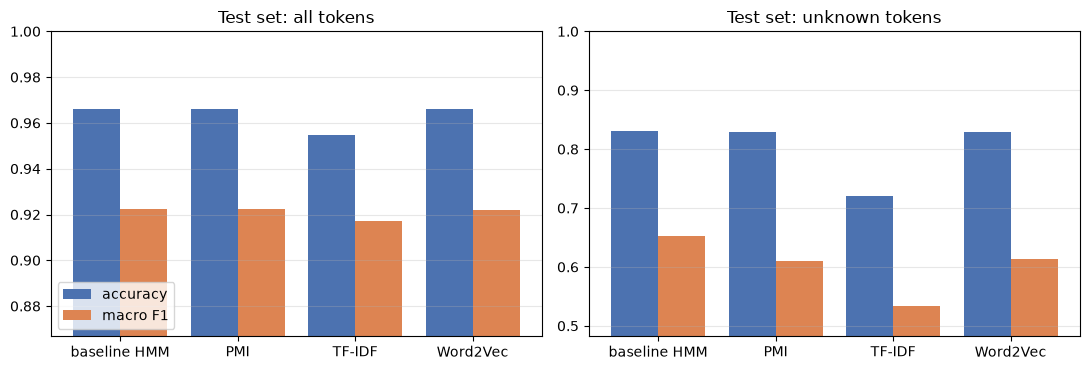

In [31]:
systems = list(all_results)
x = np.arange(len(systems))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, subset in zip(axes, ["all", "unknown"]):
    accs = [all_results[s][subset]["accuracy"] for s in systems]
    f1s = [all_results[s][subset]["macro_f1"] for s in systems]
    ax.bar(x - 0.2, accs, 0.4, label="accuracy", color="#4C72B0")
    ax.bar(x + 0.2, f1s, 0.4, label="macro F1", color="#DD8452")
    ax.set_xticks(x, [s.replace("-assisted", "") for s in systems])
    lo = min(accs + f1s)
    ax.set_ylim(lo - 0.05, 1.0)
    ax.set_title(f"Test set: {subset} tokens")
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower left")
plt.tight_layout(); plt.savefig(OUTPUTS / "part3_comparison.png", dpi=120); plt.show()

## 3.3 Error Analysis

In [32]:
def oov_errors(hmm_model, words_sents, gold_sents, pred_sents, max_show=8):
    errors = []
    for ws, gs, ps in zip(words_sents, gold_sents, pred_sents):
        for i, (w, g, p) in enumerate(zip(ws, gs, ps)):
            if hmm_model.is_oov(w) and g != p:
                ctx = " ".join(ws[max(0,i-3):i]) + f" [{w}] " + " ".join(ws[i+1:i+4])
                errors.append((w, g, p, ctx))
    return errors

base_errs  = oov_errors(hmm,       test_words, test_gold, test_pred)
pmi_errs   = oov_errors(pmi_hmm,   test_words, test_gold, pmi_pred)
tfidf_errs = oov_errors(tfidf_hmm, test_words, test_gold, tfidf_pred)
w2v_errs   = oov_errors(w2v_hmm,   test_words, test_gold, w2v_pred)

print(f"OOV error counts:  baseline={len(base_errs)}  PMI={len(pmi_errs)}  "
      f"TF-IDF={len(tfidf_errs)}  Word2Vec={len(w2v_errs)}")

# --- Show errors fixed by embedding-assisted systems ---
base_error_set = {(w, g, p, ctx) for w, g, p, ctx in base_errs}
print("\n--- Errors FIXED by PMI (baseline wrong, PMI correct) ---")
shown = 0
for ws, gs, bp, pp in zip(test_words, test_gold, test_pred, pmi_pred):
    for i, (w, g, b, p) in enumerate(zip(ws, gs, bp, pp)):
        if pmi_hmm.is_oov(w) and g != b and g == p and shown < 6:
            ctx = " ".join(ws[max(0,i-3):i]) + f" [{w}] " + " ".join(ws[i+1:i+4])
            print(f"  gold={g:>5}  base={b:<5}  PMI={p:<5}  {ctx}")
            shown += 1

print("\n--- Errors FIXED by Word2Vec (baseline wrong, W2V correct) ---")
shown = 0
for ws, gs, bp, pp in zip(test_words, test_gold, test_pred, w2v_pred):
    for i, (w, g, b, p) in enumerate(zip(ws, gs, bp, pp)):
        if w2v_hmm.is_oov(w) and g != b and g == p and shown < 6:
            ctx = " ".join(ws[max(0,i-3):i]) + f" [{w}] " + " ".join(ws[i+1:i+4])
            print(f"  gold={g:>5}  base={b:<5}  W2V={p:<5}  {ctx}")
            shown += 1

print("\n--- Errors INTRODUCED by embeddings (baseline correct, embedding wrong) ---")
shown = 0
for ws, gs, bp, pp, tp in zip(test_words, test_gold, test_pred, pmi_pred, w2v_pred):
    for i, (w, g, b, p, t) in enumerate(zip(ws, gs, bp, pp, tp)):
        if pmi_hmm.is_oov(w) and g == b and (g != p or g != t) and shown < 6:
            ctx = " ".join(ws[max(0,i-3):i]) + f" [{w}] " + " ".join(ws[i+1:i+4])
            print(f"  gold={g:>5}  base={b:<5}  PMI={p:<5}  W2V={t:<5}  {ctx}")
            shown += 1

OOV error counts:  baseline=583  PMI=587  TF-IDF=958  Word2Vec=589

--- Errors FIXED by PMI (baseline wrong, PMI correct) ---
  gold=  VBG  base=JJ     PMI=VBG     [Satisfying] its interests was
  gold=   JJ  base=RB     PMI=JJ     Hotline to accept [business-to-business] help .
  gold=   NN  base=JJ     PMI=NN     stem the AIDS [epidemic] because it suggests
  gold=   NN  base=JJ     PMI=NN     meeting of AIDS [vaccine] researchers in Florida

--- Errors FIXED by Word2Vec (baseline wrong, W2V correct) ---
  gold=  VBG  base=NNP    W2V=VBG    book review `` [Kissing] Nature Good-bye ''
  gold=  VBN  base=JJ     W2V=VBN    `` Everybody 's [confused] and no one
  gold=   NN  base=JJ     W2V=NN     shelves of some [mass-merchandise] , discount retailers

--- Errors INTRODUCED by embeddings (baseline correct, embedding wrong) ---
  gold=  NNP  base=NNP    PMI=DT     W2V=NNP     [Globe] columnist Mike Barnicle
  gold=   NN  base=NN     PMI=NN     W2V=PRP    `` [Everybody] was afraid of
  go

In [33]:
# What the representations retrieve for a few unknown words: neighbours -> averaged emission's top tag
def explain(word, ctx_sentence, pos):
    print(f"\n[{word}]  gold={gold_of[(word, pos)]}  in: {' '.join(ctx_sentence[max(0,pos-3):pos+4])}")
    for name, h in [("PMI", pmi_hmm), ("TF-IDF", tfidf_hmm), ("Word2Vec", w2v_hmm)]:
        em = h.embedding_model
        nbrs = em.most_similar(word, top_k=5)
        how = "word"
        if not nbrs:
            l, r = max(0, pos - h.ctx_window), min(len(ctx_sentence), pos + h.ctx_window + 1)
            nbrs = em.most_similar_from_context([w for i, w in enumerate(ctx_sentence[l:r], start=l) if i != pos], top_k=5)
            how = "context"
        e = h._embedding_emission(ctx_sentence, pos)
        top = h.tags[int(np.argmax(e))] if e is not None else "-"
        print(f"  {name:<9}({how:<7}) -> emission argmax {top:<5} | " + ", ".join(f"{w}" for w, _ in nbrs))

gold_of = {}
examples = []
for ws, gs in zip(test_words, test_gold):
    for i, (w, g) in enumerate(zip(ws, gs)):
        if w in {"epidemic", "torque", "Everybody", "Globe", "confused"} and (w, i) not in gold_of:
            gold_of[(w, i)] = g
            examples.append((w, ws, i))
seen = set()
for w, ws, i in examples:
    if w not in seen:
        seen.add(w); explain(w, ws, i)


[torque]  gold=NN  in: pressure floor , torque box , fixed
  PMI      (context) -> emission argmax VB    | otc, allocate, adverse, mounting, bolster
  TF-IDF   (context) -> emission argmax VBN   | pressure, floor, box, fixed, franc
  Word2Vec (context) -> emission argmax SYM   | lender, fishing, tuitions, winner, calculation

[Globe]  gold=NNP  in: The Boston Globe says its newly
  PMI      (context) -> emission argmax VBN   | tires, walls, aew, merged, strip


  TF-IDF   (context) -> emission argmax TO    | the, its, says, of, boston
  Word2Vec (context) -> emission argmax VBZ   | bargaining, disarray, papers, texaco, s.c

[Everybody]  gold=NN  in: `` Everybody was afraid of


  PMI      (context) -> emission argmax SYM   | cambodian, bricks, purpose, flowers, gallery
  TF-IDF   (word   ) -> emission argmax MD    | trim, relax, agrees, give, want
  Word2Vec (word   ) -> emission argmax VBG   | demands, near-term, reclaim, knowing, assassination

[confused]  gold=VBN  in: `` Everybody 's confused and no one
  PMI      (context) -> emission argmax NN    | watt, exception, amazing, solution, accident
  TF-IDF   (context) -> emission argmax POS   | and, 's, one, no, the
  Word2Vec (context) -> emission argmax SYM   | oh, implication, football, furthermore, appointments

[epidemic]  gold=NN  in: that the AIDS epidemic `` may reduce
  PMI      (context) -> emission argmax NN    | dependence, concept, seniority, pinnacle, europa


  TF-IDF   (context) -> emission argmax DT    | the, that, may, reduce, of
  Word2Vec (context) -> emission argmax SYM   | trough, figuring, fishing, lender, holder


## 3.4 Discussion: When Representations Help or Hurt

**Headline result.** No embedding-assisted system beats the baseline HMM on the test set:

| system | all acc | unknown acc | unknown macro-F1 |
|---|---|---|---|
| baseline HMM | **0.9662** | **0.8302** | **0.653** |
| PMI-assisted | 0.9661 | 0.8290 | 0.610 |
| TF-IDF-assisted | 0.9546 | 0.7209 | 0.533 |
| Word2Vec-assisted | 0.9659 | 0.8284 | 0.614 |

This matches validation, where the best $\alpha$ was the smallest or second-smallest value in the grid for every
representation (PMI 0.1, TF-IDF 0.1, Word2Vec 0.2). Accuracy fell steadily as $\alpha$ grew, so the tuning was
already telling us to trust the signatures more than the embeddings. PMI and Word2Vec stay within 0.2 pt of the
baseline on unknown words (they fix about as many errors as they introduce), while TF-IDF clearly hurts. Word2Vec is
the only one that was slightly *better* than the baseline on validation (unknown acc 84.66% vs 84.56%), but that
+0.1 pt (one token out of 952) did not carry over to the test set (82.84% vs 83.02%). A difference that small is noise. Known-word accuracy barely
changes for any system, because only unknown words' emissions are modified. The small drop for TF-IDF on known words
is errors spreading through the transitions.

**Why the gains are small: the embeddings rarely "see" an unknown word.** The embeddings are trained on the same
training split as the HMM. Only **14–15%** of unknown test tokens have a vector at all, and only through lowercasing
or `<NUM>` normalisation (e.g. *Everybody → everybody*). The other ~85% rely on the **context fallback**, which finds
words that fit the *surrounding* ±3 tokens. That is a much weaker and noisier signal about the word itself.

**When they help.** The fixes are open-class nouns and participles in a clear syntactic frame. Examples are *the AIDS
[epidemic] because* and *meeting of AIDS [vaccine] researchers* (baseline JJ → NN with PMI), *accept
[business-to-business] help* (RB → JJ with PMI), *Everybody 's [confused] and* (JJ → VBN with Word2Vec), *some
[mass-merchandise] , discount retailers* (JJ → NN with Word2Vec) and *`` [Kissing] Nature Good-bye* (NNP → VBG with
Word2Vec). In these cases the
signature (no suffix, or an ambiguous one) leaves NN/JJ almost tied. A small push from neighbours that are mostly
nouns or participles is enough to tip Viterbi the right way, which is why a small $\alpha$ works best.

**When they hurt.**
* **TF-IDF retrieves function words.** Sentence-level TF-IDF neighbours of a context bag are the words that share the
  most *sentences* with it, i.e. *the, of, its, says, and, 's* (see the neighbour lists for *Globe*, *confused* and
  *epidemic* above). Their emission columns are dominated by DT / IN / POS, so the averaged emission pulls an unknown
  noun toward closed-class tags. The 958 vs 583 OOV errors come mostly from this.
* **Topical rather than syntactic neighbours.** For *torque* (gold NN) the PMI context neighbours are *otc, allocate,
  adverse, mounting, bolster*, and the Word2Vec ones are *lender, fishing, tuitions, winner*. These are mixed-POS words, so their
  averaged emission points to VB / SYM. Sentence-initial capitalised words suffer the same way with Word2Vec:
  *[Factories] operated* → RB and *[Measured] the same way* → VBG, both of which the baseline had right. In *[Globe] columnist*, the PMI-assisted system outputs DT.
* **Bias of averaging $P(w\mid t)$.** The method averages *emission probabilities* $P(w'\mid t)$ of the neighbours.
  These are large for **small tags** (SYM, TO, POS, MD), where every member word has a large share of the tag's mass.
  As a result, the argmax of the averaged emission is often a rare tag (SYM for *torque*, *confused* and *epidemic*
  under Word2Vec, TO for *Globe* under TF-IDF). The baseline's signature term is a proper $P(\text{sig}\mid\text{UNK},t)$ distribution and does not have
  this problem, so interpolating with it at small $\alpha$ is what keeps the system from breaking.
* **Rare-word neighbours (Word2Vec).** On a 190k-token corpus, many low-frequency words have poorly trained vectors.
  *Everybody* (→ *everybody*) lands next to *demands, near-term, reclaim, knowing, assassination*, which pushes it to PRP / VBG even
  though the baseline already had NN right.

**Sparse vs dense.** Of the two sparse models, **PMI with a narrow (±2) window** behaves like a syntactic model and is
roughly harmless. **TF-IDF with whole sentences as documents** behaves like a topic model and is actively harmful for
POS tagging, because topic does not predict word class. **Word2Vec** has the most syntactic neighbours for in-vocabulary
words (best POS-agreement in Part 1), is the cheapest to query (~3 s to decode the test set, vs ~1 min for PMI and
~3 min for TF-IDF), and ties with the baseline. For POS tagging, the representation needs to capture *syntactic substitutability*
(small windows); topical relatedness does not help.

**What would make embeddings pay off.** (1) Train the embeddings on a much larger unlabeled corpus, so that words
unseen by the HMM actually have vectors. This is the main reason embedding-based OOV handling works in practice.
(2) Average the neighbours' **posteriors** $P(t\mid w')$ and convert back with Bayes' rule
($P(w\mid t)\propto P(t\mid w)/P(t)$) instead of averaging $P(w\mid t)$, which removes the small-tag bias. (3) Only use
neighbours with similarity above a threshold, and skip function-word neighbours in the context fallback.